In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid

In [2]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
print(dhs.shape)
#Loading biosample embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
decomp_Basis = np.load(fn)
#Loading DHS embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
decomp_Mixture = np.load(fn)
print(decomp_Mixture.shape)
print(decomp_Basis.shape)
dhs_array = dhs.to_numpy()
n_biosamples, n_biosample_e = decomp_Basis.shape
n_DHS_e, n_DHSs = decomp_Mixture.shape
print(n_biosamples, n_DHSs)

(733, 3591898)
(16, 3591898)
(733, 16)
733 3591898


In [3]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_1_cycle=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
new_decomp_Basis_all_delta_0001_1_cycle=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_2_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
new_decomp_Basis_all_delta_0001_2_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_2_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_3_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
new_decomp_Basis_all_delta_0001_3_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_3_cycles=pickle.load(pickle_in)

In [4]:
nmf_comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
# color = ['grey', 'darkorchid', 'deepskyblue', 'slateblue', 'orange', 'slategrey', 'gold', 'royalblue', 'green', 'saddlebrown', 'chocolate', 'olivedrab', 'seagreen', 'darkolivegreen', 'red', 'darkblue']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

In [5]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])

tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")
biosample_df = df[['library order', 'Biosample name']]

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [6]:
DHS_metadata_identifiers = np.array(DHS_metadata['identifier'])

In [7]:
DHS_metadata['ind'] = DHS_metadata.index
DHS_metadata_identifier_based = DHS_metadata.set_index(['identifier'])
DHS_metadata_identifier_based

,seqname,start,end,mean_signal,numsamples,summit,core_start,core_end,component,ind
identifier,,,,,,,,,,
1.10011,chr1,16140,16200,0.129388,1,16170,16170,16170,Tissue invariant,0
1.10021,chr1,51868,52040,0.0800339,1,51970,51970,51970,Placental / trophoblast,1
1.10025,chr1,57280,57354,0.2732505,4,57350,57350,57350,Neural,2
1.10027,chr1,66370,66482,0.183715575,8,66430,66410,66430,Primitive / embryonic,3
1.1003,chr1,79100,79231,0.113049,2,79150,79150,79150,Placental / trophoblast,4
...,...,...,...,...,...,...,...,...,...,...
Y.994281,chrY,56882540,56882719,0.038079,1,56882610,56882610.0,56882610.0,Lymphoid,3591893
Y.994286,chrY,56882864,56882980,0.115489,1,56882930,56882930.0,56882930.0,Lymphoid,3591894
Y.994292,chrY,56883733,56883960,0.491377,5,56883830,56883742.0,56883870.0,Placental / trophoblast,3591895


In [8]:
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)
DHS_metadata_sortby_mean_signal = DHS_metadata.sort_values(['mean_signal'], ascending=False)
top_10_percent_DHSs = DHS_metadata_sortby_mean_signal.iloc[:int(np.round(n_DHSs/10))]
top_10_percent_DHSs_inds = np.array(top_10_percent_DHSs['ind'])
top_10_percent_DHSs_identifiers = np.array(top_10_percent_DHSs['identifier'])

In [8]:
#The component number for the summary data corresponds to the NMF component
comp0 = pd.read_table('/home/ctrader/lightfm_data/comp1_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp0 mean'])
comp1 = pd.read_table('/home/ctrader/lightfm_data/comp2_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp1 mean'])
comp2 = pd.read_table('/home/ctrader/lightfm_data/comp3_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp2 mean'])
comp3 = pd.read_table('/home/ctrader/lightfm_data/comp4_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp3 mean'])
comp4 = pd.read_table('/home/ctrader/lightfm_data/comp5_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp4 mean'])
comp5 = pd.read_table('/home/ctrader/lightfm_data/comp6_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp5 mean'])
comp6 = pd.read_table('/home/ctrader/lightfm_data/comp7_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp6 mean'])
comp7 = pd.read_table('/home/ctrader/lightfm_data/comp8_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp7 mean'])
comp8 = pd.read_table('/home/ctrader/lightfm_data/comp9_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp8 mean'])
comp9 = pd.read_table('/home/ctrader/lightfm_data/comp10_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp9 mean'])
comp10 = pd.read_table('/home/ctrader/lightfm_data/comp11_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp10 mean'])
comp11 = pd.read_table('/home/ctrader/lightfm_data/comp12_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp11 mean'])
comp12 = pd.read_table('/home/ctrader/lightfm_data/comp13_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp12 mean'])
comp13 = pd.read_table('/home/ctrader/lightfm_data/comp14_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp13 mean'])
comp14 = pd.read_table('/home/ctrader/lightfm_data/comp15_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp14 mean'])
comp15 = pd.read_table('/home/ctrader/lightfm_data/comp16_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp15 mean'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (0) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [9]:
all_comps_average_signal = comp0[['name', 'comp0 mean']].merge(comp1[['name', 'comp1 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp2[['name', 'comp2 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp3[['name', 'comp3 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp4[['name', 'comp4 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp5[['name', 'comp5 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp6[['name', 'comp6 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp7[['name', 'comp7 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp8[['name', 'comp8 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp9[['name', 'comp9 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp10[['name', 'comp10 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp11[['name', 'comp11 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp12[['name', 'comp12 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp13[['name', 'comp13 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp14[['name', 'comp14 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp15[['name', 'comp15 mean']], how='inner', on='name')
all_comps_average_signal['average over all comps'] = all_comps_average_signal.mean(axis=1)
# all_comps_average_signal['average over all comps'] = (all_comps_average_signal['comp0 mean'] + all_comps_average_signal['comp1 mean'] + all_comps_average_signal['comp2 mean'] + all_comps_average_signal['comp3 mean'] + all_comps_average_signal['comp4 mean'] + all_comps_average_signal['comp5 mean'] + all_comps_average_signal['comp6 mean'] + all_comps_average_signal['comp7 mean'] + all_comps_average_signal['comp8 mean'] + all_comps_average_signal['comp9 mean'] + all_comps_average_signal['comp10 mean'] + all_comps_average_signal['comp11 mean'] + all_comps_average_signal['comp12 mean'] + all_comps_average_signal['comp13 mean'] + all_comps_average_signal['comp14 mean'] + all_comps_average_signal['comp15 mean'])/16
all_comps_average_signal['name'] = all_comps_average_signal['name'].astype(str)
all_comps_average_signal = all_comps_average_signal.set_index(['name'])
# old_columns = list(all_comps_average_signal.columns).extend(['max signal'])
# all_comps_average_signal.columns = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
all_comps_average_signal['max signal'] = all_comps_average_signal.idxmax(axis=1)
# all_comps_average_signal.columns = old_columns



all_comps_average_signal = all_comps_average_signal.loc[DHS_metadata_identifiers]
top_10_percent_T_F = np.array([False]*len(all_comps_average_signal))
top_10_percent_T_F[top_10_percent_DHSs_inds] = True
all_comps_average_signal['top 10 percent'] = top_10_percent_T_F
all_comps_average_signal

/tmp/ipykernel_73492/3344514459.py:16: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  all_comps_average_signal['average over all comps'] = all_comps_average_signal.mean(axis=1)


,comp0 mean,comp1 mean,comp2 mean,comp3 mean,comp4 mean,comp5 mean,comp6 mean,comp7 mean,comp8 mean,comp9 mean,comp10 mean,comp11 mean,comp12 mean,comp13 mean,comp14 mean,comp15 mean,average over all comps,max signal,top 10 percent
name,,,,,,,,,,,,,,,,,,,
1.10011,0.053318,0.046712,0.039907,0.034054,0.029935,0.019642,0.050381,0.044771,0.038645,0.052703,0.028230,0.073723,0.043809,0.059390,0.188392,0.038370,0.052624,comp14 mean,False
1.10021,0.012199,0.006616,0.009675,0.005551,0.009631,0.015424,0.037962,0.003689,0.003913,0.006651,0.014848,0.009479,0.012386,0.008923,0.008113,0.004985,0.010628,comp6 mean,False
1.10025,0.013972,0.010649,0.002742,0.005082,0.004388,0.004117,0.010228,0.085321,0.003772,0.005397,0.006319,0.011102,0.003377,0.002977,0.005027,0.015383,0.011866,comp7 mean,False
1.10027,0.002374,0.003701,0.025612,0.018267,0.005331,0.021985,0.032393,0.008670,0.010130,0.010930,0.006678,0.003414,0.000000,0.005247,0.015185,0.002535,0.010778,comp6 mean,False
1.1003,0.017845,0.008636,0.009204,0.007383,0.013745,0.008851,0.032531,0.006222,0.006340,0.007592,0.031536,0.004111,0.014399,0.013492,0.006270,0.012739,0.012556,comp6 mean,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Y.994281,0.016663,0.013051,0.006976,0.008886,0.013321,0.019894,0.044953,0.010084,0.012202,0.006862,0.017083,0.012507,0.017318,0.012432,0.019537,0.017870,0.015602,comp6 mean,False
Y.994286,0.003373,0.007940,0.003355,0.002987,0.008398,0.005565,0.007886,0.005332,0.002115,0.004837,0.001810,0.005148,0.001989,0.004099,0.007139,0.003393,0.004710,comp4 mean,False
Y.994292,0.034594,0.021025,0.013023,0.017206,0.024326,0.086499,0.231924,0.011905,0.017295,0.018428,0.025081,0.018944,0.029714,0.030595,0.021135,0.143163,0.046554,comp6 mean,False


In [10]:
original_decomp_Mixture_top_comps = np.argmax(decomp_Mixture, axis=0)
new_decomp_Mixture_all_delta_0001_1_cycle_top_comps = np.argmax(new_decomp_Mixture_all_delta_0001_1_cycle, axis=0)
new_decomp_Mixture_all_delta_0001_2_cycles_top_comps = np.argmax(new_decomp_Mixture_all_delta_0001_2_cycles, axis=0)
new_decomp_Mixture_all_delta_0001_3_cycles_top_comps = np.argmax(new_decomp_Mixture_all_delta_0001_3_cycles, axis=0)

In [11]:
#filtering out indices where all comps=0, all delta 0.0001
new_decomp_Mixture_all_delta_0001_1_cycle_sum = np.sum(new_decomp_Mixture_all_delta_0001_1_cycle, axis=0)
new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered = np.where(new_decomp_Mixture_all_delta_0001_1_cycle_sum==0, np.nan, new_decomp_Mixture_all_delta_0001_1_cycle_top_comps)

new_decomp_Mixture_all_delta_0001_2_cycles_sum = np.sum(new_decomp_Mixture_all_delta_0001_2_cycles, axis=0)
new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered = np.where(new_decomp_Mixture_all_delta_0001_2_cycles_sum==0, np.nan, new_decomp_Mixture_all_delta_0001_2_cycles_top_comps)

new_decomp_Mixture_all_delta_0001_3_cycles_sum = np.sum(new_decomp_Mixture_all_delta_0001_3_cycles, axis=0)
new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered = np.where(new_decomp_Mixture_all_delta_0001_3_cycles_sum==0, np.nan, new_decomp_Mixture_all_delta_0001_3_cycles_top_comps)

In [12]:
#For each cycle, collecting information about the DHSs that belong to each component
DHSs_for_each_comp_0_cycles = []
DHSs_for_each_comp_identifiers_0_cycles = []
DHSs_for_each_comp_mean_comp_signal_0_cycles = []
DHSs_for_each_comp_numsamples_0_cycles = []
for comp in range(16):
    top_comp_dhss = np.where(original_decomp_Mixture_top_comps==comp)
    DHSs_for_each_comp_0_cycles.append(top_comp_dhss)
    numsamples = DHS_metadata.loc[top_comp_dhss]['numsamples'].astype(int)
    DHSs_for_each_comp_numsamples_0_cycles.append(list(numsamples))
    identifiers = DHS_metadata.loc[top_comp_dhss]['identifier'].astype(str)
    DHSs_for_each_comp_identifiers_0_cycles.append(identifiers)
    DHSs_for_each_comp_mean_comp_signal_0_cycles.append(list(all_comps_average_signal.loc[identifiers]['comp' + str(comp) + ' mean']))
    
DHSs_for_each_comp_1_cycle = []
DHSs_for_each_comp_identifiers_1_cycle = []
DHSs_for_each_comp_mean_comp_signal_1_cycle = []
DHSs_for_each_comp_numsamples_1_cycle = []
DHSs_dropped_cycle_1 = []
DHSs_added_cycle_1 = []
for comp in range(16):
    top_comp_dhss = np.where(new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered==comp)
    DHSs_for_each_comp_1_cycle.append(top_comp_dhss)
    DHSs_added_cycle_1.append(np.sort(np.array(list(set(DHSs_for_each_comp_1_cycle[comp][0]) - set(DHSs_for_each_comp_0_cycles[comp][0])))))
    DHSs_dropped_cycle_1.append(np.sort(np.array(list(set(DHSs_for_each_comp_0_cycles[comp][0]) - set(DHSs_for_each_comp_1_cycle[comp][0])))))
    numsamples = DHS_metadata.loc[top_comp_dhss]['numsamples'].astype(int)
    DHSs_for_each_comp_numsamples_1_cycle.append(list(numsamples))
    identifiers = DHS_metadata.loc[top_comp_dhss]['identifier'].astype(str)
    DHSs_for_each_comp_identifiers_1_cycle.append(identifiers)
    DHSs_for_each_comp_mean_comp_signal_1_cycle.append(list(all_comps_average_signal.loc[identifiers]['comp' + str(comp) + ' mean']))
    
DHSs_for_each_comp_2_cycles = []
DHSs_for_each_comp_identifiers_2_cycles = []
DHSs_for_each_comp_mean_comp_signal_2_cycles = []
DHSs_for_each_comp_numsamples_2_cycles = []
DHSs_dropped_cycle_2 = []
DHSs_added_cycle_2 = []
for comp in range(16):
    top_comp_dhss = np.where(new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered==comp)
    DHSs_for_each_comp_2_cycles.append(top_comp_dhss)
    DHSs_added_cycle_2.append(np.sort(np.array(list(set(DHSs_for_each_comp_2_cycles[comp][0]) - set(DHSs_for_each_comp_1_cycle[comp][0])))))
    DHSs_dropped_cycle_2.append(np.sort(np.array(list(set(DHSs_for_each_comp_1_cycle[comp][0]) - set(DHSs_for_each_comp_2_cycles[comp][0])))))
    numsamples = DHS_metadata.loc[top_comp_dhss]['numsamples'].astype(int)
    DHSs_for_each_comp_numsamples_2_cycles.append(list(numsamples))
    identifiers = DHS_metadata.loc[top_comp_dhss]['identifier'].astype(str)
    DHSs_for_each_comp_identifiers_2_cycles.append(identifiers)
    DHSs_for_each_comp_mean_comp_signal_2_cycles.append(list(all_comps_average_signal.loc[identifiers]['comp' + str(comp) + ' mean']))
    
DHSs_for_each_comp_3_cycles = []
DHSs_for_each_comp_identifiers_3_cycles = []
DHSs_for_each_comp_mean_comp_signal_3_cycles = []
DHSs_for_each_comp_numsamples_3_cycles = []
DHSs_dropped_cycle_3 = []
DHSs_added_cycle_3 = []
for comp in range(16):
    top_comp_dhss = np.where(new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered==comp)
    DHSs_for_each_comp_3_cycles.append(top_comp_dhss)
    DHSs_added_cycle_3.append(np.sort(np.array(list(set(DHSs_for_each_comp_3_cycles[comp][0]) - set(DHSs_for_each_comp_2_cycles[comp][0])))))
    DHSs_dropped_cycle_3.append(np.sort(np.array(list(set(DHSs_for_each_comp_2_cycles[comp][0]) - set(DHSs_for_each_comp_3_cycles[comp][0])))))
    numsamples = DHS_metadata.loc[top_comp_dhss]['numsamples'].astype(int)
    DHSs_for_each_comp_numsamples_3_cycles.append(list(numsamples))
    identifiers = DHS_metadata.loc[top_comp_dhss]['identifier'].astype(str)
    DHSs_for_each_comp_identifiers_3_cycles.append(identifiers)
    DHSs_for_each_comp_mean_comp_signal_3_cycles.append(list(all_comps_average_signal.loc[identifiers]['comp' + str(comp) + ' mean']))
    
DHSs_added_cycle_1_identifiers = []
DHSs_added_cycle_2_identifiers = []
DHSs_added_cycle_3_identifiers = []
for i in range(16):
    DHSs_added_cycle_1_identifiers.append(DHS_metadata.loc[DHSs_added_cycle_1[i]]['identifier'])
    DHSs_added_cycle_2_identifiers.append(DHS_metadata.loc[DHSs_added_cycle_2[i]]['identifier'])
    DHSs_added_cycle_3_identifiers.append(DHS_metadata.loc[DHSs_added_cycle_3[i]]['identifier'])

In [13]:
#find the percent of DHSs that are classified by the component with the highest signal value
DHS_metadata = DHS_metadata.sort_values(['ind'])
all_indetifiers = np.array(DHS_metadata['identifier'])
all_comps_average_signal_dhs_ind_ordered = all_comps_average_signal.loc[all_indetifiers]
all_comps_average_signal_dhs_ind_ordered['max signal comp ind'] = all_comps_average_signal_dhs_ind_ordered['max signal'].str.replace('comp', '').str.replace(' mean', '').astype(int)
all_comps_average_signal_dhs_ind_ordered['original top comps'] = original_decomp_Mixture_top_comps
all_comps_average_signal_dhs_ind_ordered['cycle 1 top comps'] = new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered
all_comps_average_signal_dhs_ind_ordered['cycle 2 top comps'] = new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered
all_comps_average_signal_dhs_ind_ordered['cycle 3 top comps'] = new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered

all_comps_average_signal_dhs_ind_ordered['number of columns larger than mean'] = np.array([0]*len(all_comps_average_signal_dhs_ind_ordered))
average_for_each_comp_top_10_percent = []
for i in range(16):
    average_for_each_comp_top_10_percent.append(np.mean(all_comps_average_signal_dhs_ind_ordered[all_comps_average_signal_dhs_ind_ordered['top 10 percent']==True]['comp'+str(i)+' mean']))
    all_comps_average_signal_dhs_ind_ordered.loc[all_comps_average_signal_dhs_ind_ordered['comp'+str(i)+' mean']>average_for_each_comp_top_10_percent[i], 'number of columns larger than mean']+=1

In [14]:
#taking the top 10% of DHSs
all_comps_average_signal_top_10_percent_ordered = all_comps_average_signal_dhs_ind_ordered.loc[top_10_percent_DHSs_identifiers]

In [15]:
mask0 = all_comps_average_signal_top_10_percent_ordered['max signal comp ind']==all_comps_average_signal_top_10_percent_ordered['original top comps']
mask1 = all_comps_average_signal_top_10_percent_ordered['max signal comp ind']==all_comps_average_signal_top_10_percent_ordered['cycle 1 top comps']
mask2 = all_comps_average_signal_top_10_percent_ordered['max signal comp ind']==all_comps_average_signal_top_10_percent_ordered['cycle 2 top comps']
mask3 = all_comps_average_signal_top_10_percent_ordered['max signal comp ind']==all_comps_average_signal_top_10_percent_ordered['cycle 3 top comps']
mask1_baseline = ~all_comps_average_signal_top_10_percent_ordered['cycle 1 top comps'].isnull()
mask2_baseline = ~all_comps_average_signal_top_10_percent_ordered['cycle 2 top comps'].isnull()
mask3_baseline = ~all_comps_average_signal_top_10_percent_ordered['cycle 3 top comps'].isnull()
print(len(all_comps_average_signal_top_10_percent_ordered[mask0 & mask3_baseline]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline]))
print(len(all_comps_average_signal_top_10_percent_ordered[mask1 & mask3_baseline]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline]))
print(len(all_comps_average_signal_top_10_percent_ordered[mask2 & mask3_baseline]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline]))
print(len(all_comps_average_signal_top_10_percent_ordered[mask3 & mask3_baseline]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline]))

0.5002697950769976
0.5007608827452407
0.5013277555474718
0.5009639869043289


In [183]:
# #stratifying by number of components the DHS shows up in
# all_comps_average_signal_top_10_percent_ordered['number of columns larger than mean'] = np.array([0]*len(all_comps_average_signal_top_10_percent_ordered))
# #finding average signal value for each column for top 10% of DHSs
# average_for_each_comp = []
# for i in range(16):
#     average_for_each_comp.append(np.mean(all_comps_average_signal_top_10_percent_ordered['comp'+str(i)+' mean']))
#     all_comps_average_signal_top_10_percent_ordered.loc[all_comps_average_signal_top_10_percent_ordered['comp'+str(i)+' mean']>average_for_each_comp[i], 'number of columns larger than mean']+=1

In [16]:
#stratifying by number of components the DHS shows up in
cycle_0_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean = []
cycle_1_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean = []
cycle_2_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean = []
cycle_3_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean = []
for i in range(17):
    comp_num_mask = all_comps_average_signal_top_10_percent_ordered['number of columns larger than mean']==i
    cycle_0_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask0 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)
    cycle_1_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask1 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)
    cycle_2_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask2 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)
    cycle_3_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask3 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)

#DHSs classified in the tissue invariant component   
# mask0_greater_than_4 = all_comps_average_signal_top_10_percent_ordered['original top comps']==0
# mask1_greater_than_4 = all_comps_average_signal_top_10_percent_ordered['cycle 1 top comps']==0
# mask2_greater_than_4 = all_comps_average_signal_top_10_percent_ordered['cycle 2 top comps']==0
# mask3_greater_than_4 = all_comps_average_signal_top_10_percent_ordered['cycle 3 top comps']==0
# for i in range(17):
#     comp_num_mask = all_comps_average_signal_top_10_percent_ordered['number of columns larger than mean']==i
#     cycle_0_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask0_greater_than_4 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)
#     cycle_1_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask1_greater_than_4 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)
#     cycle_2_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask2_greater_than_4 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)
#     cycle_3_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask3_greater_than_4 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)

Text(0.5, 1.0, 'Percent of DHSs Classified in the "Optimal" Component Stratified by Number of Components in which DHS is Present\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

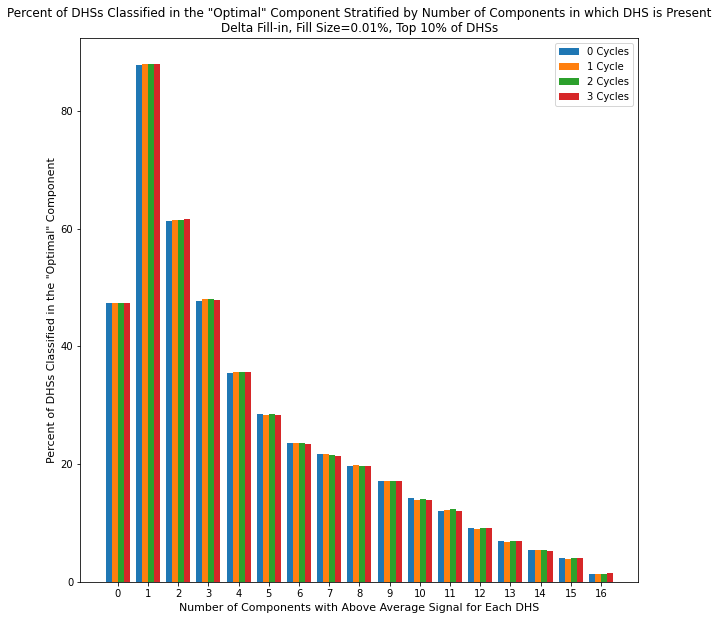

In [17]:
data = [cycle_0_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean, cycle_1_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean, cycle_2_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean, cycle_3_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean]
 
fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')


plt.bar(np.arange(17)-0.3, data[0], width=0.2)
plt.bar(np.arange(17)-0.1, data[1], width=0.2)
plt.bar(np.arange(17)+0.1, data[2], width=0.2)
plt.bar(np.arange(17)+0.3, data[3], width=0.2)
plt.xticks(np.arange(17), ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16'])
plt.xlabel('Number of Components with Above Average Signal for Each DHS', fontsize=11)
plt.ylabel('Percent of DHSs Classified in the "Optimal" Component', fontsize=11)
plt.legend(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'])
plt.title('Percent of DHSs Classified in the "Optimal" Component Stratified by Number of Components in which DHS is Present\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=12)

In [76]:
#finding the number of components each added dhs is present in
cycle_1_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean = []
cycle_2_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean = []
cycle_3_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean = []
for i in range(16):
    DHSs_added_cycle_1_df = all_comps_average_signal_dhs_ind_ordered.loc[DHSs_added_cycle_1_identifiers[i]]
    DHSs_added_cycle_2_df = all_comps_average_signal_dhs_ind_ordered.loc[DHSs_added_cycle_2_identifiers[i]]
    DHSs_added_cycle_3_df = all_comps_average_signal_dhs_ind_ordered.loc[DHSs_added_cycle_3_identifiers[i]]
    DHSs_added_cycle_1_df = DHSs_added_cycle_1_df[DHSs_added_cycle_1_df['top 10 percent']==True]
    DHSs_added_cycle_2_df = DHSs_added_cycle_2_df[DHSs_added_cycle_2_df['top 10 percent']==True]
    DHSs_added_cycle_3_df = DHSs_added_cycle_3_df[DHSs_added_cycle_3_df['top 10 percent']==True]  
    cycle_1_added_dhs_nums_comp_specific = []
    cycle_2_added_dhs_nums_comp_specific = []
    cycle_3_added_dhs_nums_comp_specific = []
    for j in range(17):
        cycle_1_added_dhs_nums_comp_specific.append(len(DHSs_added_cycle_1_df[DHSs_added_cycle_1_df['number of columns larger than mean']==j]))
        cycle_2_added_dhs_nums_comp_specific.append(len(DHSs_added_cycle_2_df[DHSs_added_cycle_2_df['number of columns larger than mean']==j]))
        cycle_3_added_dhs_nums_comp_specific.append(len(DHSs_added_cycle_3_df[DHSs_added_cycle_3_df['number of columns larger than mean']==j]))
    cycle_1_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean.append(cycle_1_added_dhs_nums_comp_specific)
    cycle_2_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean.append(cycle_2_added_dhs_nums_comp_specific)
    cycle_3_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean.append(cycle_3_added_dhs_nums_comp_specific)

Text(0.5, 1.03, 'DHSs Added to Each Component After 3 Cycles Stratified by Number of Components in which DHS is Present\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

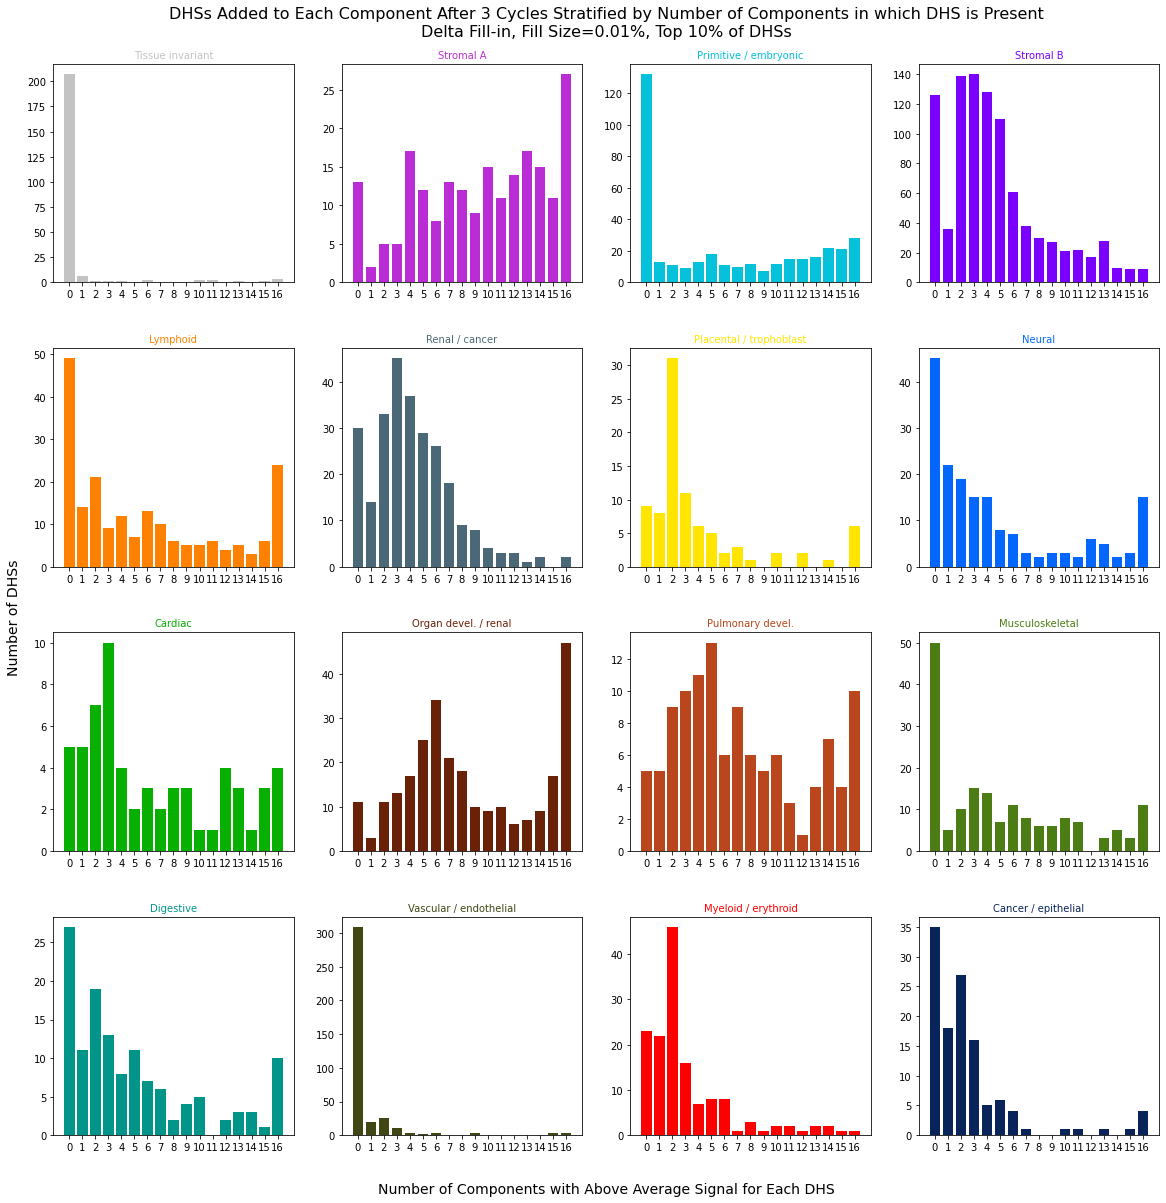

In [92]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.3)
fig.patch.set_facecolor('white')

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    data = [cycle_1_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean[ind], cycle_2_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean[ind], cycle_3_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean[ind]]
    ax.bar(np.arange(17), data[2], log=False, color=color[ind])
    
    ax.set_xticks(list(np.arange(17)))
    
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])
#     ax.legend(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'])
    
fig.text(0.5, 0.0, 'Number of Components with Above Average Signal for Each DHS', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('DHSs Added to Each Component After 3 Cycles Stratified by Number of Components in which DHS is Present\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.03)

In [116]:
top_10_percent_DHSs_inds

array([     63, 1598356, 1598102, ..., 1357091, 2315567,  761224])

In [123]:
new_decomp_Mixture_all_delta_0001_1_cycle[:, 2315567]

array([0.        , 0.00436984, 0.        , 0.00579168, 0.00509745,
       0.        , 0.        , 0.0003485 , 0.        , 0.00279348,
       0.00145731, 0.        , 0.        , 0.00315534, 0.06611594,
       0.        ])

In [124]:
new_decomp_Mixture_all_delta_0001_1_cycle[:, top_10_percent_DHSs_inds]

(16, 359190)

In [9]:
#quantitatively comparing mixture embeddings
cycle_1_mixture_original_difference = new_decomp_Mixture_all_delta_0001_1_cycle[:, top_10_percent_DHSs_inds] - decomp_Mixture[:, top_10_percent_DHSs_inds]
cycle_2_mixture_original_difference = new_decomp_Mixture_all_delta_0001_2_cycles[:, top_10_percent_DHSs_inds] - decomp_Mixture[:, top_10_percent_DHSs_inds]
cycle_3_mixture_original_difference = new_decomp_Mixture_all_delta_0001_3_cycles[:, top_10_percent_DHSs_inds] - decomp_Mixture[:, top_10_percent_DHSs_inds]

In [22]:
# sum of difference across comps
cycle_1_mixture_original_difference_sum_comps = np.sum(cycle_1_mixture_original_difference, axis=1)
cycle_2_mixture_original_difference_sum_comps = np.sum(cycle_2_mixture_original_difference, axis=1)
cycle_3_mixture_original_difference_sum_comps = np.sum(cycle_3_mixture_original_difference, axis=1)

Text(0.5, 1.0, "Sum of Difference Between Each Cycle's Mixture and Original Mixture Embeddings Across Each Component\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs")

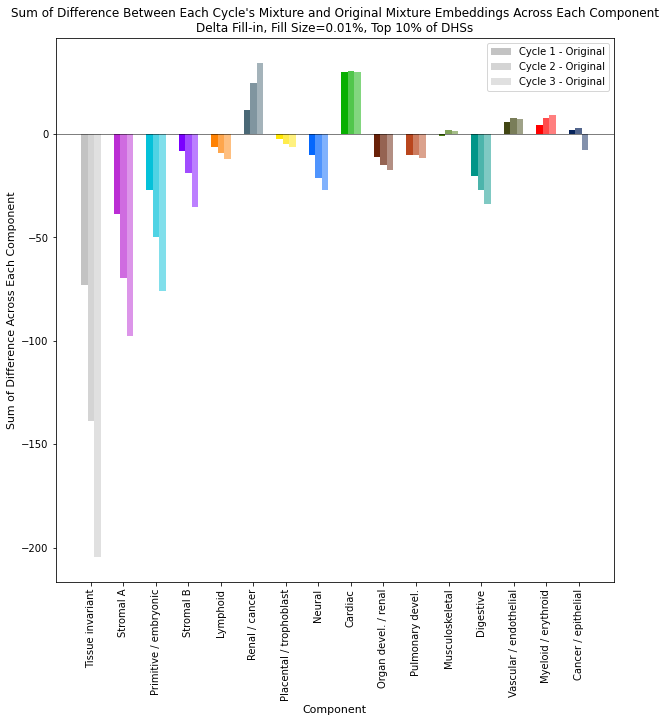

In [23]:
fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')

plt.bar(np.arange(16)-0.2, cycle_1_mixture_original_difference_sum_comps, width=0.2, color=color, alpha=1)
plt.bar(np.arange(16), cycle_2_mixture_original_difference_sum_comps, width=0.2, color=color, alpha=0.7)
plt.bar(np.arange(16)+0.2, cycle_3_mixture_original_difference_sum_comps, width=0.2, color=color, alpha=0.5)
plt.xticks(np.arange(16), nmf_comps, rotation=90)
plt.xlabel('Component', fontsize=11)
plt.ylabel('Sum of Difference Across Each Component', fontsize=11)
plt.legend(['Cycle 1 - Original', 'Cycle 2 - Original', 'Cycle 3 - Original'])
plt.axhline(y=0, color='k', linewidth=0.5)
plt.title('Sum of Difference Between Each Cycle\'s Mixture and Original Mixture Embeddings Across Each Component\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=12)

In [24]:
a = np.array([3, 0])
b = np.array([0, 4])
print(a.shape)
print(np.sum(a-b))
print(np.sqrt(np.sum(np.square(a-b))))
print(np.linalg.norm(a-b))

(2,)
-1
5.0
5.0


In [13]:
#Euclidean distance for each comp
cycle_1_mixture_original_euclidean_distance_comps = np.sqrt(np.sum(np.square(cycle_1_mixture_original_difference), axis=1))
cycle_2_mixture_original_euclidean_distance_comps = np.sqrt(np.sum(np.square(cycle_2_mixture_original_difference), axis=1))
cycle_3_mixture_original_euclidean_distance_comps = np.sqrt(np.sum(np.square(cycle_3_mixture_original_difference), axis=1))

In [39]:
(DHS_metadata[DHS_metadata['component']=='Primitive / embryonic']['numsamples'].astype(int))

3            8
18          69
23          32
24          15
28         156
          ... 
3591825     11
3591830      4
3591847      1
3591865     16
3591866      8
Name: numsamples, Length: 626541, dtype: int64

Text(0.5, 1.0, "Euclidean Distance Between Each Cycle's Mixture and Original Mixture Embeddings Across Each Component\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs")

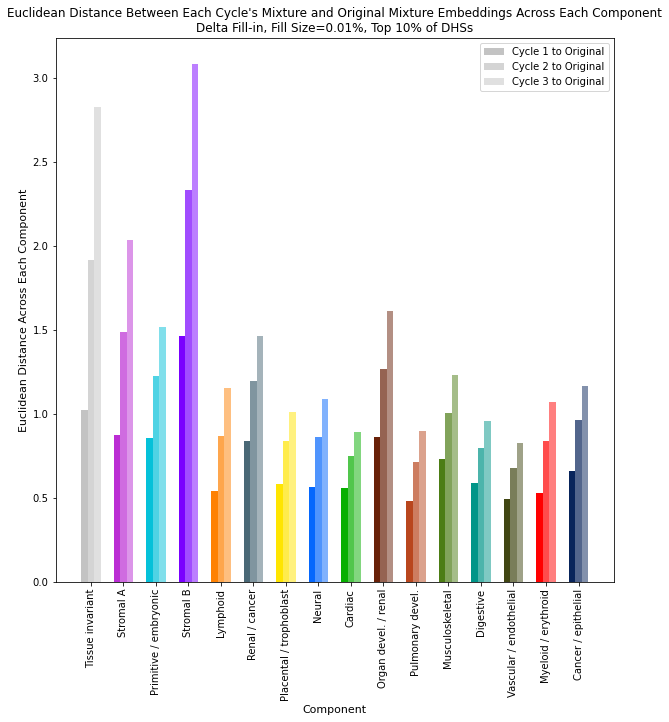

In [14]:
fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')

plt.bar(np.arange(16)-0.2, cycle_1_mixture_original_euclidean_distance_comps, width=0.2, color=color, alpha=1)
plt.bar(np.arange(16), cycle_2_mixture_original_euclidean_distance_comps, width=0.2, color=color, alpha=0.7)
plt.bar(np.arange(16)+0.2, cycle_3_mixture_original_euclidean_distance_comps, width=0.2, color=color, alpha=0.5)
plt.xticks(np.arange(16), nmf_comps, rotation=90)
plt.xlabel('Component', fontsize=11)
plt.ylabel('Euclidean Distance Across Each Component', fontsize=11)
plt.legend(['Cycle 1 to Original', 'Cycle 2 to Original', 'Cycle 3 to Original'])
# plt.axhline(y=0, color='k', linewidth=0.5)
plt.title('Euclidean Distance Between Each Cycle\'s Mixture and Original Mixture Embeddings Across Each Component\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=12)

In [15]:
#Euclidean distance for each DHS
cycle_1_mixture_original_euclidean_distance_dhss = np.sqrt(np.sum(np.square(cycle_1_mixture_original_difference), axis=0))
cycle_2_mixture_original_euclidean_distance_dhss = np.sqrt(np.sum(np.square(cycle_2_mixture_original_difference), axis=0))
cycle_3_mixture_original_euclidean_distance_dhss = np.sqrt(np.sum(np.square(cycle_3_mixture_original_difference), axis=0))

In [16]:
nmf_comp_color_dict = {nmf_comps[i]: color[i] for i in range(len(nmf_comps))}

In [17]:
DHS_metadata_ind_sorted = DHS_metadata.sort_values(['ind'])
DHS_metadata_ind_sorted_top_10_percent = DHS_metadata_ind_sorted.loc[top_10_percent_DHSs_inds]
DHS_metadata_ind_sorted_top_10_percent['numsamples'] = DHS_metadata_ind_sorted_top_10_percent['numsamples'].astype(int)
top_10_percent_sorted_numsamples = np.array(DHS_metadata_ind_sorted_top_10_percent['numsamples'])
top_10_percent_sorted_mean_signal = np.array(DHS_metadata_ind_sorted_top_10_percent['mean_signal'])
top_10_percent_sorted_component = np.array(DHS_metadata_ind_sorted_top_10_percent['component'])
top_10_percent_sorted_component_colors = np.array([nmf_comp_color_dict[i] for i in top_10_percent_sorted_component])

Text(0.5, 1.0, 'Euclidean Distance Between Cycle 1 and Original Mixture Embeddings Across Each DHS Compared to Number of Samples\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

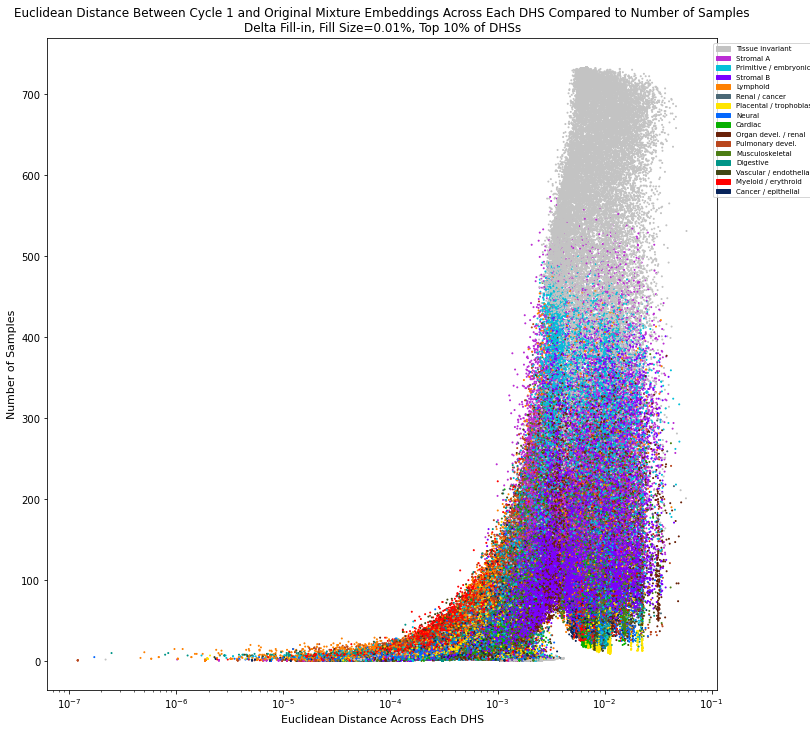

In [72]:
fig = plt.figure(figsize=(12,12))
fig.patch.set_facecolor('white')

plt.scatter(cycle_1_mixture_original_euclidean_distance_dhss, top_10_percent_sorted_numsamples, c=top_10_percent_sorted_component_colors, s=1)

plt.xlabel('Euclidean Distance Across Each DHS', fontsize=11)
plt.ylabel('Number of Samples', fontsize=11)
plt.xscale('log')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, nmf_comps, loc = (0.88, 0.73), prop={'size': 7})
# plt.legend(['Cycle 1 to Original', 'Cycle 2 to Original', 'Cycle 3 to Original'])
# plt.axhline(y=0, color='k', linewidth=0.5)
plt.title('Euclidean Distance Between Cycle 1 and Original Mixture Embeddings Across Each DHS Compared to Number of Samples\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=12)

Text(0.5, 1.03, 'Euclidean Distance Between Cycle 1 and Original Mixture Embeddings Across Each DHS Compared to Number of Samples\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs, Stratified by Original DHS Component')

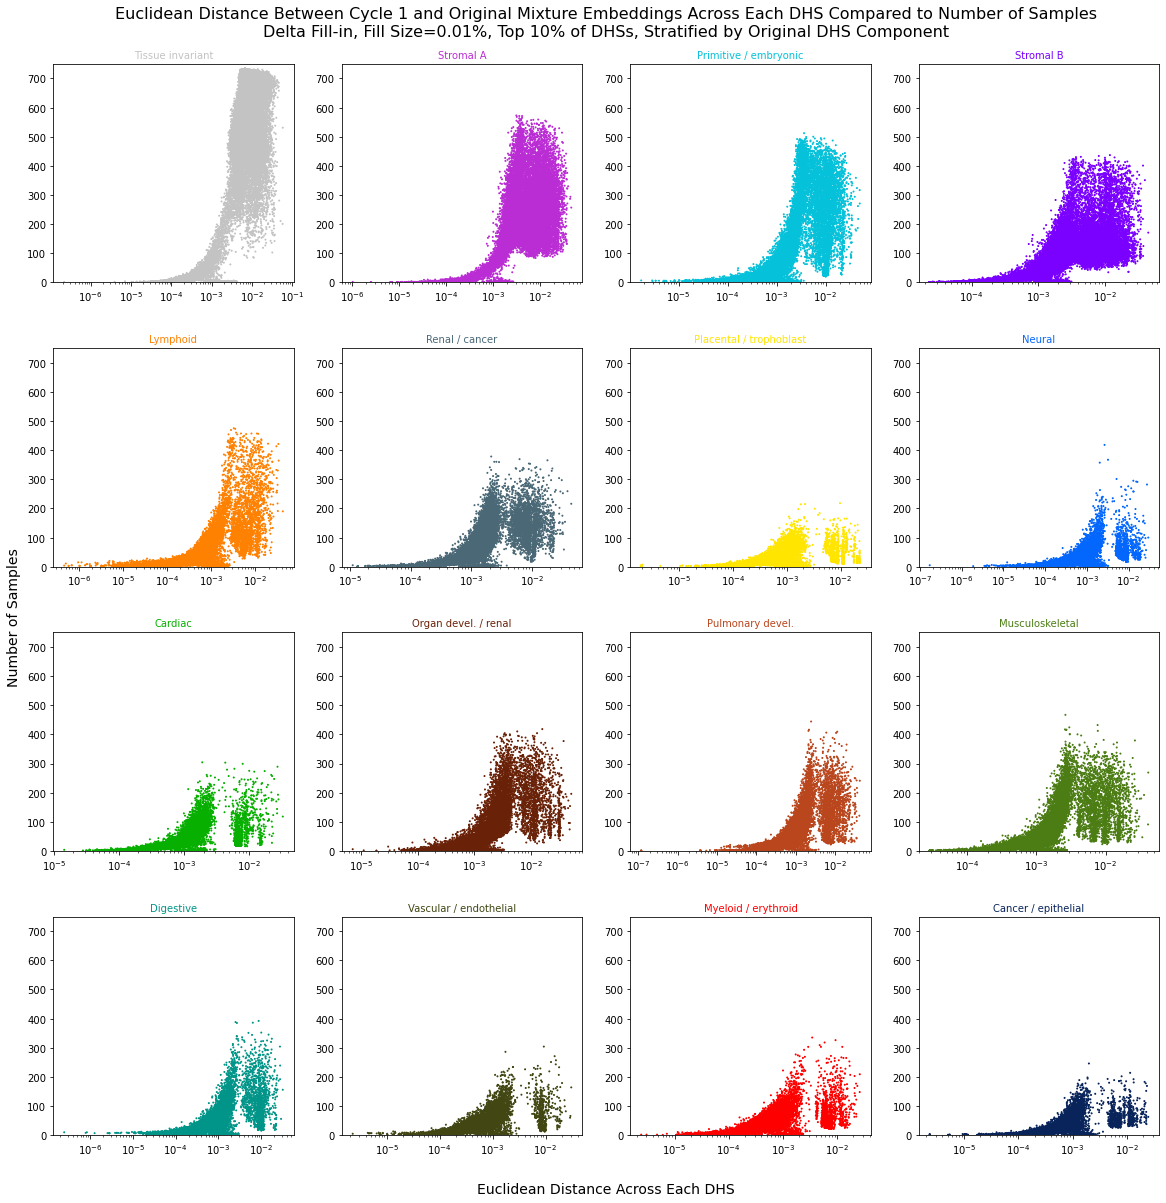

In [89]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.3)
fig.patch.set_facecolor('white')

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    comp_dhss = np.where(top_10_percent_sorted_component==nmf_comps[ind])
    ax.scatter(cycle_1_mixture_original_euclidean_distance_dhss[comp_dhss], top_10_percent_sorted_numsamples[comp_dhss], c=top_10_percent_sorted_component_colors[comp_dhss], s=1)
    
    ax.set_xscale('log')
    ax.set_ylim([0, 750])
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])

# handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
# fig.legend(handles, nmf_comps, loc = (0.88, 0.73), prop={'size': 7})
# plt.legend(['Cycle 1 to Original', 'Cycle 2 to Original', 'Cycle 3 to Original'])
# plt.axhline(y=0, color='k', linewidth=0.5)
fig.text(0.5, 0.0, 'Euclidean Distance Across Each DHS', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Number of Samples', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Euclidean Distance Between Cycle 1 and Original Mixture Embeddings Across Each DHS Compared to Number of Samples\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs, Stratified by Original DHS Component', fontsize=16, x=0.5, y=1.03)

Text(0.5, 1.0, 'Euclidean Distance Between Cycle 3 and Original Mixture Embeddings Across Each DHS Compared to Mean Signal\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

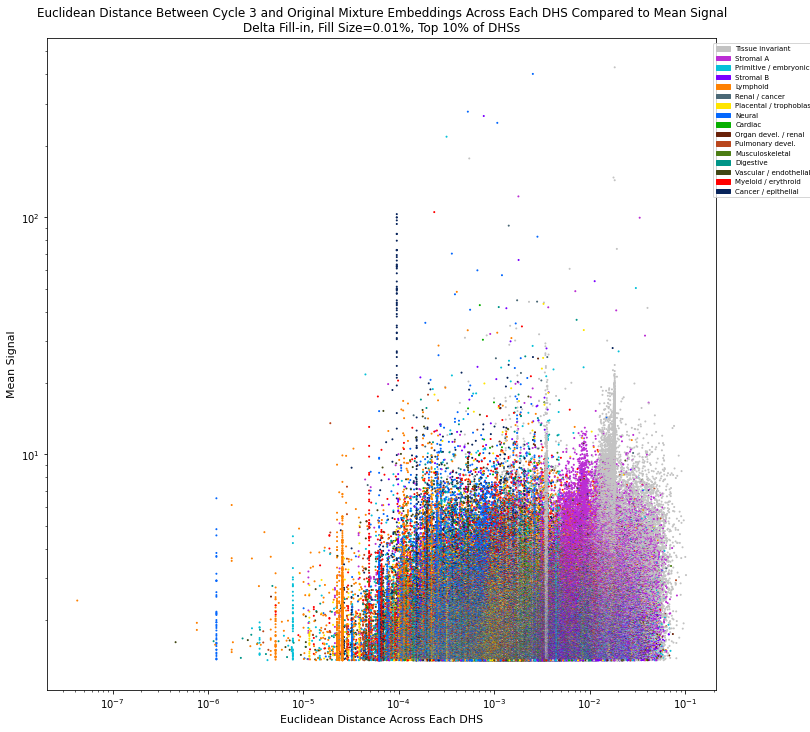

In [30]:
fig = plt.figure(figsize=(12,12))
fig.patch.set_facecolor('white')

plt.scatter(cycle_3_mixture_original_euclidean_distance_dhss, top_10_percent_sorted_mean_signal, c=top_10_percent_sorted_component_colors, s=1)

plt.xlabel('Euclidean Distance Across Each DHS', fontsize=11)
plt.ylabel('Mean Signal', fontsize=11)
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, nmf_comps, loc = (0.88, 0.73), prop={'size': 7})
plt.yscale('log')
plt.xscale('log')
plt.title('Euclidean Distance Between Cycle 3 and Original Mixture Embeddings Across Each DHS Compared to Mean Signal\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=12)

Text(0.5, 1.03, 'Euclidean Distance Between Cycle 1 and Original Mixture Embeddings Across Each DHS Compared to Mean Signal\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs, Stratified by Original DHS Component')

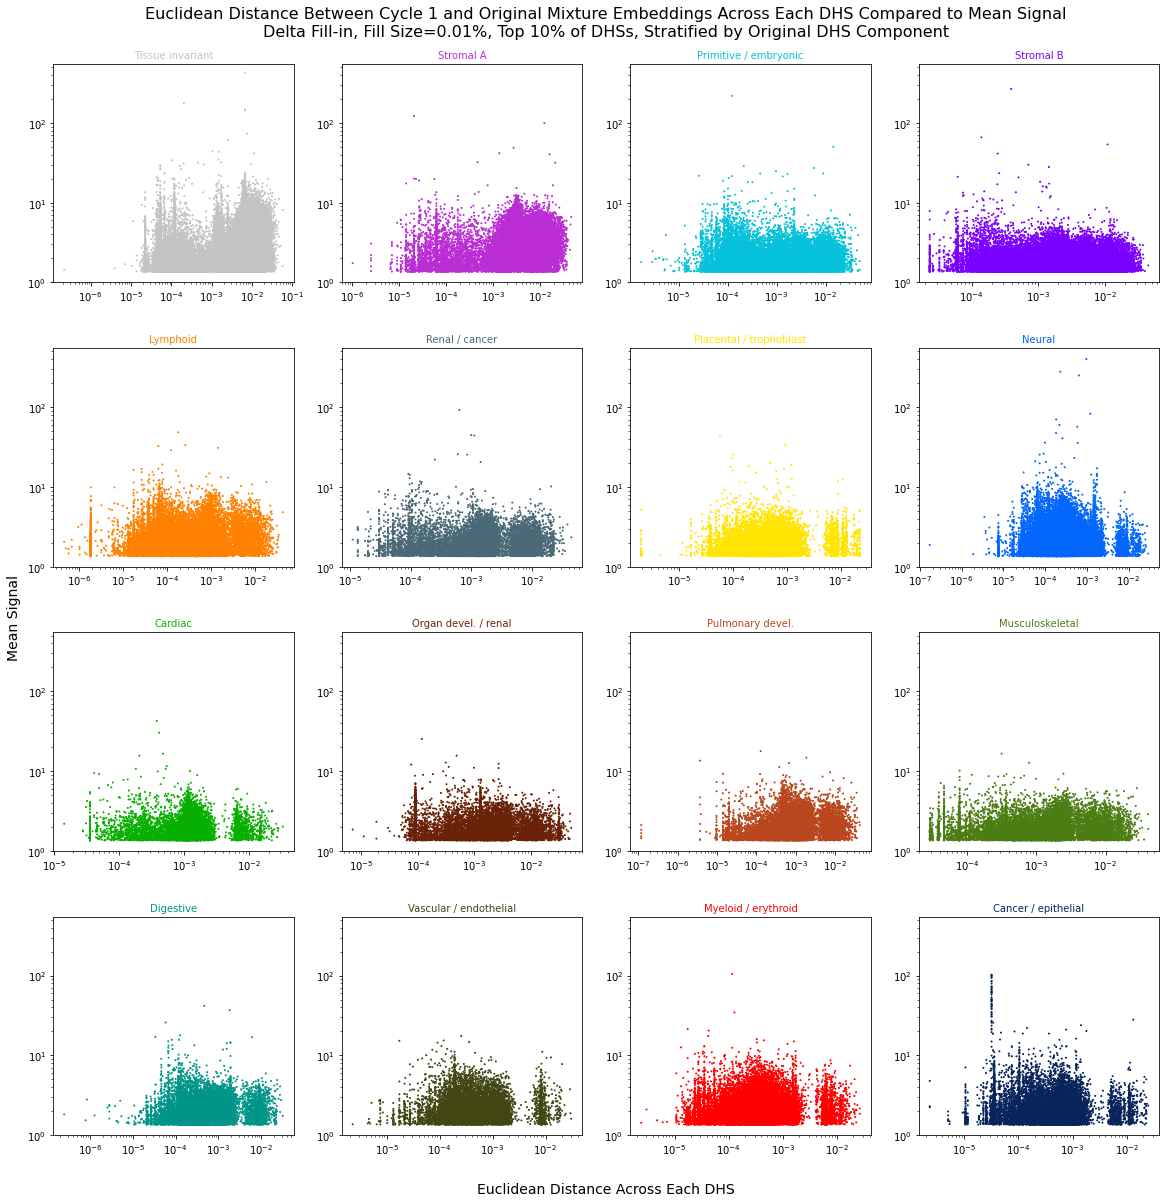

In [85]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.3)
fig.patch.set_facecolor('white')

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    comp_dhss = np.where(top_10_percent_sorted_component==nmf_comps[ind])
    ax.scatter(cycle_1_mixture_original_euclidean_distance_dhss[comp_dhss], top_10_percent_sorted_mean_signal[comp_dhss], c=top_10_percent_sorted_component_colors[comp_dhss], s=1)
    
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylim([1, 550])
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])

# handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
# fig.legend(handles, nmf_comps, loc = (0.88, 0.73), prop={'size': 7})
# plt.legend(['Cycle 1 to Original', 'Cycle 2 to Original', 'Cycle 3 to Original'])
# plt.axhline(y=0, color='k', linewidth=0.5)
fig.text(0.5, 0.0, 'Euclidean Distance Across Each DHS', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Mean Signal', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Euclidean Distance Between Cycle 1 and Original Mixture Embeddings Across Each DHS Compared to Mean Signal\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs, Stratified by Original DHS Component', fontsize=16, x=0.5, y=1.03)

In [13]:
#violin plots
cycle_0_top_10_percent_dhss_average_over_all_comps = []
cycle_0_top_10_percent_dhss_comp_specific_mean_signal = []
for i in range(16):
    DHSs = DHS_metadata.loc[DHSs_for_each_comp_0_cycles[i][0]]['identifier'].astype(str)
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    DHS_signal_values_df = DHS_signal_values_df[DHS_signal_values_df['top 10 percent']==True]
    cycle_0_top_10_percent_dhss_average_over_all_comps.append(np.array(DHS_signal_values_df['average over all comps']))
    cycle_0_top_10_percent_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))

cycle_1_added_top_10_percent_dhss_average_over_all_comps = []
cycle_1_added_top_10_percent_dhss_comp_specific_mean_signal = []
for i in range(16):
    DHSs = DHS_metadata.loc[DHSs_added_cycle_1[i]]['identifier'].astype(str)
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    DHS_signal_values_df = DHS_signal_values_df[DHS_signal_values_df['top 10 percent']==True]
    cycle_1_added_top_10_percent_dhss_average_over_all_comps.append(np.array(DHS_signal_values_df['average over all comps']))
    cycle_1_added_top_10_percent_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))

cycle_2_added_top_10_percent_dhss_average_over_all_comps = []
cycle_2_added_top_10_percent_dhss_comp_specific_mean_signal = []
for i in range(16):
    DHSs = DHS_metadata.loc[DHSs_added_cycle_2[i]]['identifier'].astype(str)
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    DHS_signal_values_df = DHS_signal_values_df[DHS_signal_values_df['top 10 percent']==True]
    cycle_2_added_top_10_percent_dhss_average_over_all_comps.append(np.array(DHS_signal_values_df['average over all comps']))
    cycle_2_added_top_10_percent_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))

cycle_3_added_top_10_percent_dhss_average_over_all_comps = []
cycle_3_added_top_10_percent_dhss_comp_specific_mean_signal = []
for i in range(16):
    DHSs = DHS_metadata.loc[DHSs_added_cycle_3[i]]['identifier'].astype(str)
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    DHS_signal_values_df = DHS_signal_values_df[DHS_signal_values_df['top 10 percent']==True]
    cycle_3_added_top_10_percent_dhss_average_over_all_comps.append(np.array(DHS_signal_values_df['average over all comps']))
    cycle_3_added_top_10_percent_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))


Text(0.5, 1.03, 'Mean Signal Values of DHSs Added to Each Component After 3 Cycles\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

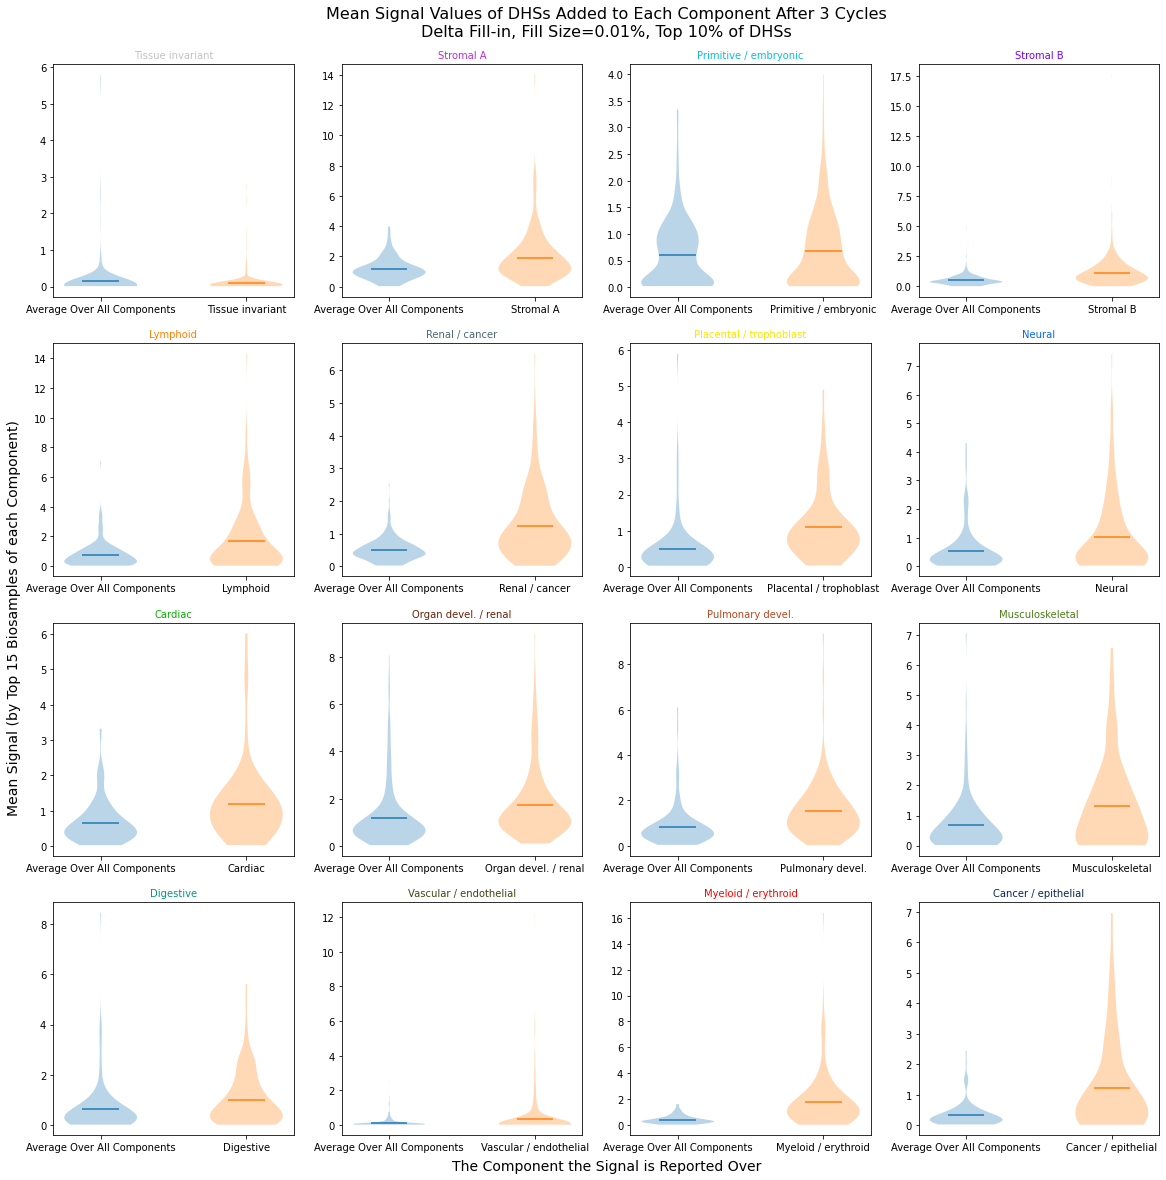

In [102]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.2)
fig.patch.set_facecolor('white')

violin_colors = ['#1f77b4', '#ff7f0e']
handles = list(plt.Rectangle((0,0),1,1, color=c, alpha=0.5) for c in violin_colors)

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    ax.violinplot(cycle_3_added_top_10_percent_dhss_average_over_all_comps[ind], positions=[0], showextrema=False, showmeans=True)
    ax.violinplot(cycle_3_added_top_10_percent_dhss_comp_specific_mean_signal[ind], positions=[1], showextrema=False, showmeans=True)
#     ax.set_ylim([0, 10])
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])
#     ax.legend(handles, ['Average Over All Components', nmf_comps[ind]])
#     ax.legend(['All Components Averaged', 'All Components Mean', nmf_comps[ind], nmf_comps[ind]+' Mean'])
#     ax.set_xticks([])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Average Over All Components', nmf_comps[ind]])




fig.text(0.5, 0.02, 'The Component the Signal is Reported Over', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Mean Signal (by Top 15 Biosamples of each Component)', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Signal Values of DHSs Added to Each Component After 3 Cycles\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.03)

In [42]:
#for each reference component, finding the signal value for the DHSs that were dropped from that component 
#across all other components
    
all_reference_comps_mean_signal_dropped_only_1_cycle = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_dropped_cycle_1[i]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_dropped_only_1_cycle.append(reference_comp)
    
all_reference_comps_mean_signal_dropped_only_2_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_dropped_cycle_2[i]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_dropped_only_2_cycles.append(reference_comp)
    
all_reference_comps_mean_signal_dropped_only_3_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_dropped_cycle_3[i]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_dropped_only_3_cycles.append(reference_comp)

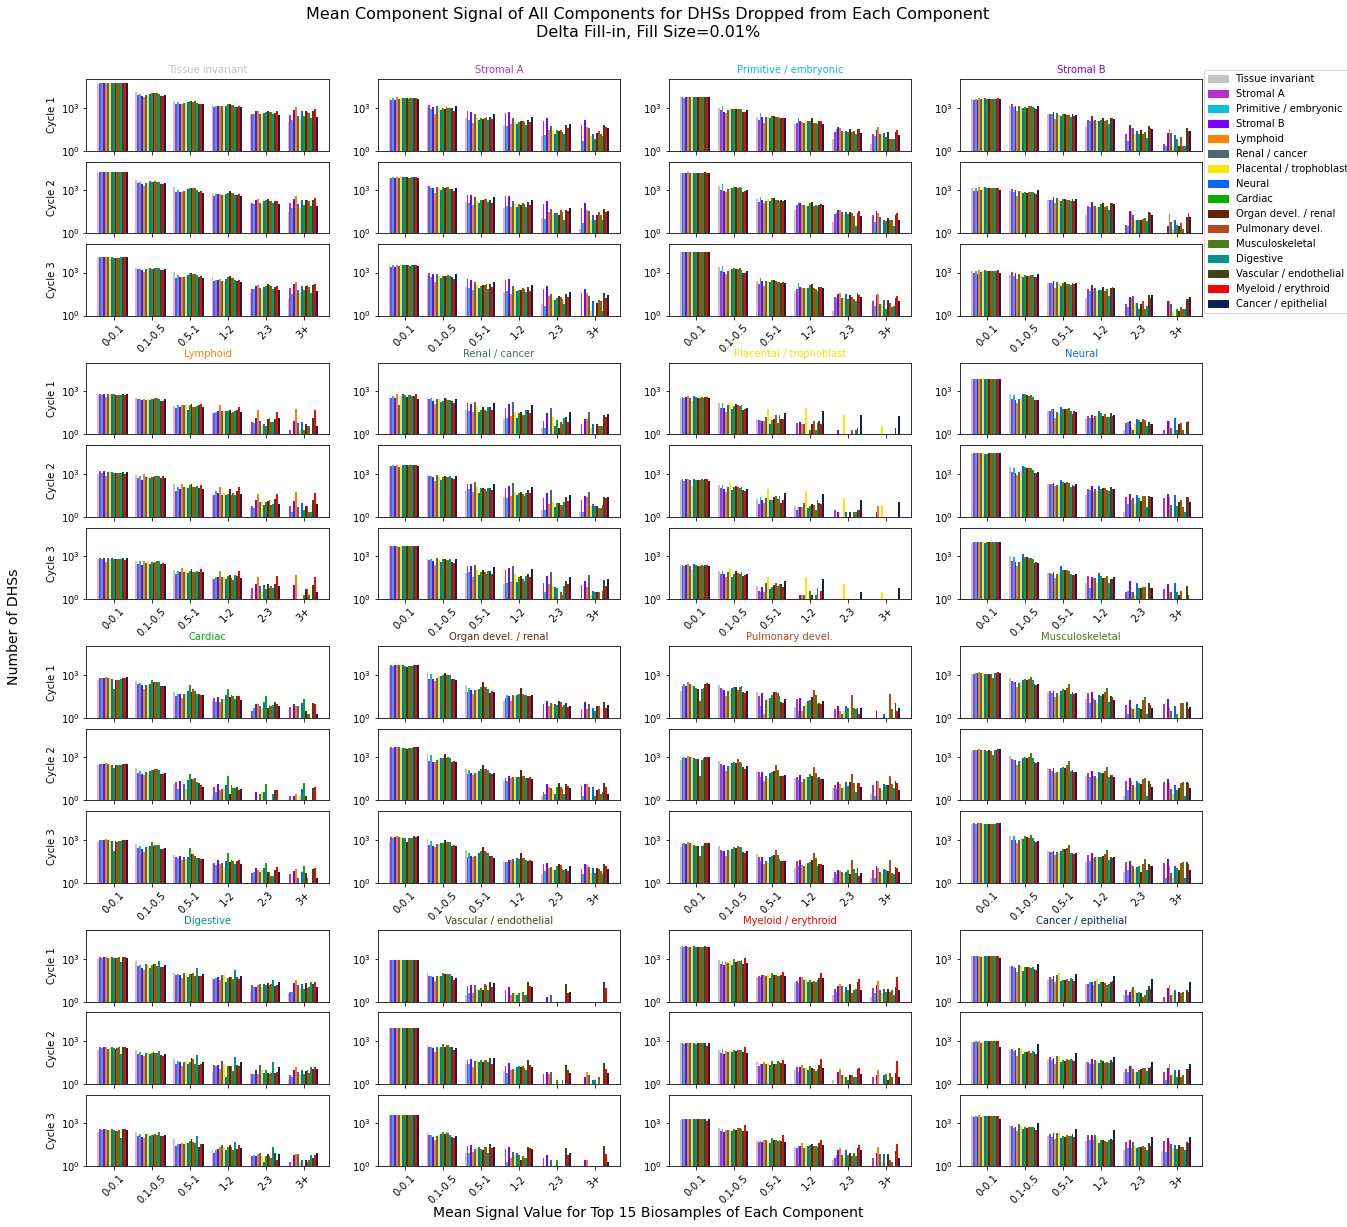

In [54]:
nrows = 4
ncols = 4
naxes = 3
bins = [0, 0.1, 0.5, 1, 2, 3, 1000.0]
fig = plt.figure(figsize=(20, 20))
fig.patch.set_facecolor('white')
for i in range(16):
    ax = axes_grid.Grid(fig, (nrows, ncols, i+1), (naxes, 1), axes_pad=0.15)
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_dropped_only_1_cycle[i][j], bins)
        ax[0].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[0].set_ylim([1, 100000])
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_dropped_only_2_cycles[i][j], bins)
        ax[1].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[1].set_ylim([1, 100000])
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_dropped_only_3_cycles[i][j], bins)
        ax[2].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[2].set_ylim([1, 100000])
        
    if i%4==0:
        ax[0].set_ylabel('Cycle 1')
        ax[1].set_ylabel('Cycle 2')
        ax[2].set_ylabel('Cycle 3')
    
#     if i//4==3:
#         ax[1].set_xlabel('3 Cycles')
    
    ax[2].set_xticks(list(np.arange(6)))
    ax[2].set_xticklabels(['0-0.1', '0.1-0.5', '0.5-1', '1-2', '2-3', '3+'], rotation=45)
    ax[0].set_title(nmf_comps[i], fontsize=10, color=color[i])

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, nmf_comps, loc = (0.893, 0.745))
fig.text(0.515, 0.09, 'Mean Signal Value for Top 15 Biosamples of Each Component', ha='center', fontsize=14)
fig.text(0.07, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Component Signal of All Components for DHSs Dropped from Each Component\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.515, y=0.93)
plt.subplots_adjust(wspace=0.2, hspace=0.2)
plt.show()

In [38]:
#for each reference component, finding the signal value for the DHSs that were added to that component 
#across all other components
    
all_reference_comps_mean_signal_added_only_1_cycle = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_added_cycle_1[i]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_added_only_1_cycle.append(reference_comp)
    
all_reference_comps_mean_signal_added_only_2_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_added_cycle_2[i]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_added_only_2_cycles.append(reference_comp)
    
all_reference_comps_mean_signal_added_only_3_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_added_cycle_3[i]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_added_only_3_cycles.append(reference_comp)

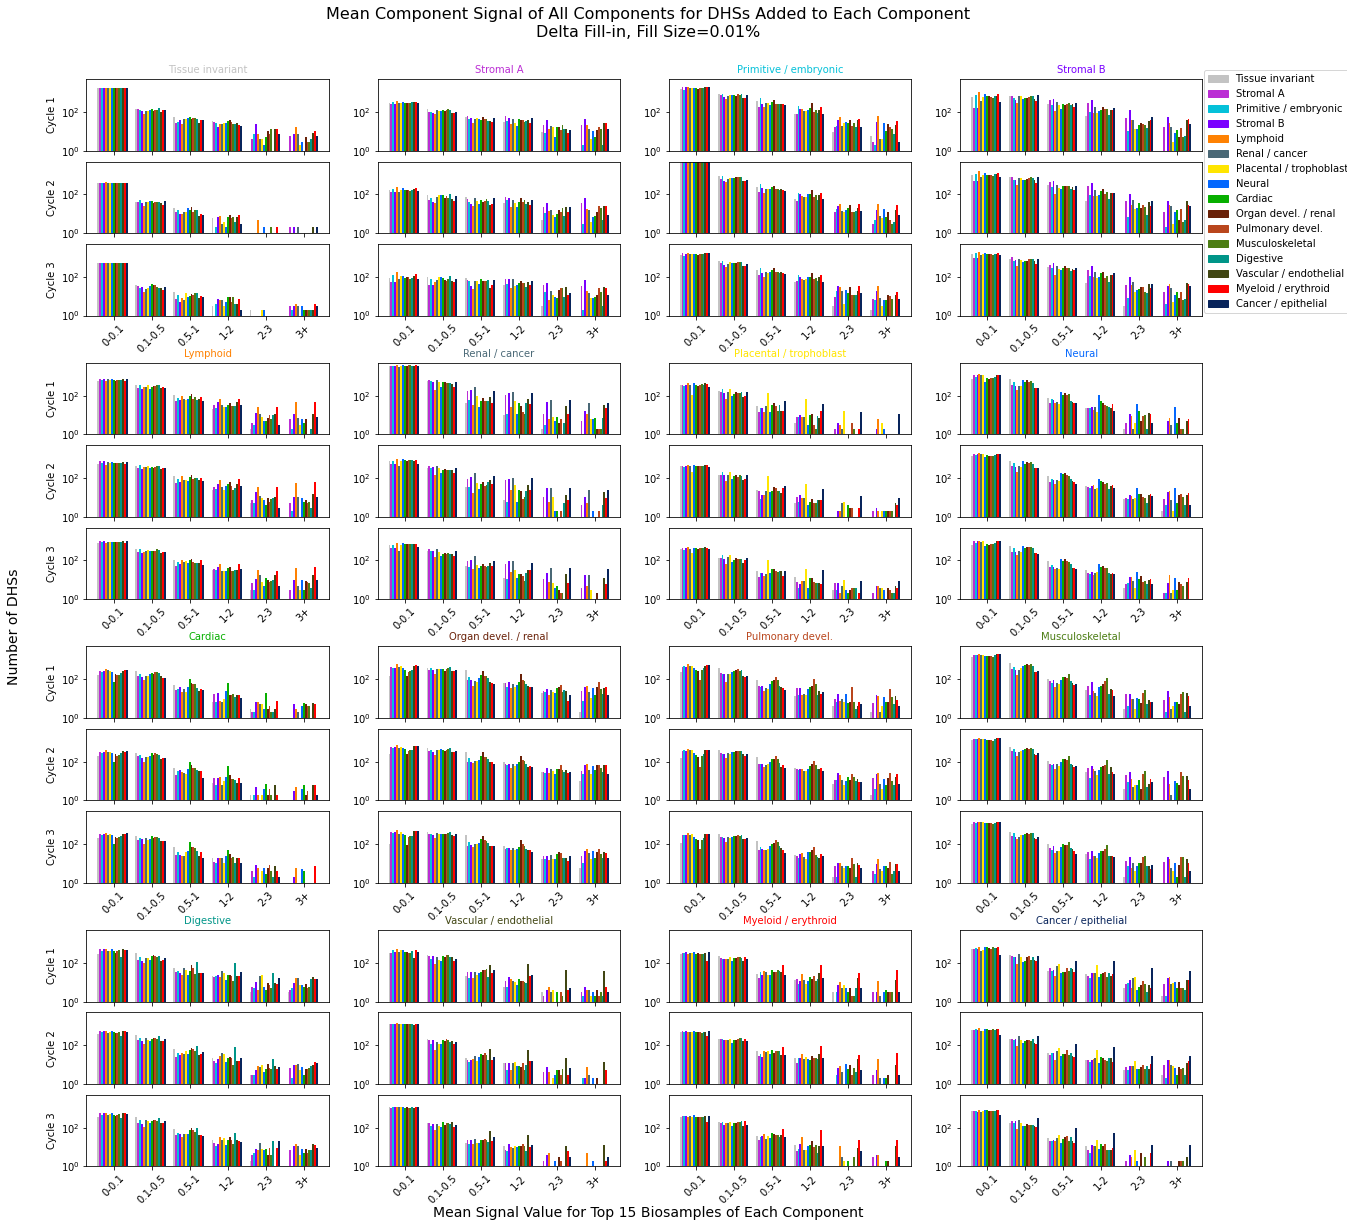

In [48]:
nrows = 4
ncols = 4
naxes = 3
bins = [0, 0.1, 0.5, 1, 2, 3, 1000.0]
fig = plt.figure(figsize=(20, 20))
fig.patch.set_facecolor('white')
for i in range(16):
    ax = axes_grid.Grid(fig, (nrows, ncols, i+1), (naxes, 1), axes_pad=0.15)
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_added_only_1_cycle[i][j], bins)
        ax[0].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[0].set_ylim([1, 5000])
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_added_only_2_cycles[i][j], bins)
        ax[1].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[1].set_ylim([1, 5000])
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_added_only_3_cycles[i][j], bins)
        ax[2].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[2].set_ylim([1, 5000])
        
    if i%4==0:
        ax[0].set_ylabel('Cycle 1')
        ax[1].set_ylabel('Cycle 2')
        ax[2].set_ylabel('Cycle 3')
    
#     if i//4==3:
#         ax[1].set_xlabel('3 Cycles')
    
    ax[2].set_xticks(list(np.arange(6)))
    ax[2].set_xticklabels(['0-0.1', '0.1-0.5', '0.5-1', '1-2', '2-3', '3+'], rotation=45)
    ax[0].set_title(nmf_comps[i], fontsize=10, color=color[i])

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, nmf_comps, loc = (0.893, 0.745))
fig.text(0.515, 0.09, 'Mean Signal Value for Top 15 Biosamples of Each Component', ha='center', fontsize=14)
fig.text(0.07, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Component Signal of All Components for DHSs Added to Each Component\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.515, y=0.93)
plt.subplots_adjust(wspace=0.2, hspace=0.2)
plt.show()

In [10]:
#for each reference component, finding the signal value for these DHSs across other components
all_reference_comps_mean_signal_0_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_for_each_comp_0_cycles[i][0]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_0_cycles.append(reference_comp)
    
all_reference_comps_mean_signal_1_cycle = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_for_each_comp_1_cycle[i][0]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_1_cycle.append(reference_comp)
    
all_reference_comps_mean_signal_2_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_for_each_comp_2_cycles[i][0]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_2_cycles.append(reference_comp)
    
all_reference_comps_mean_signal_3_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_for_each_comp_3_cycles[i][0]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_3_cycles.append(reference_comp)

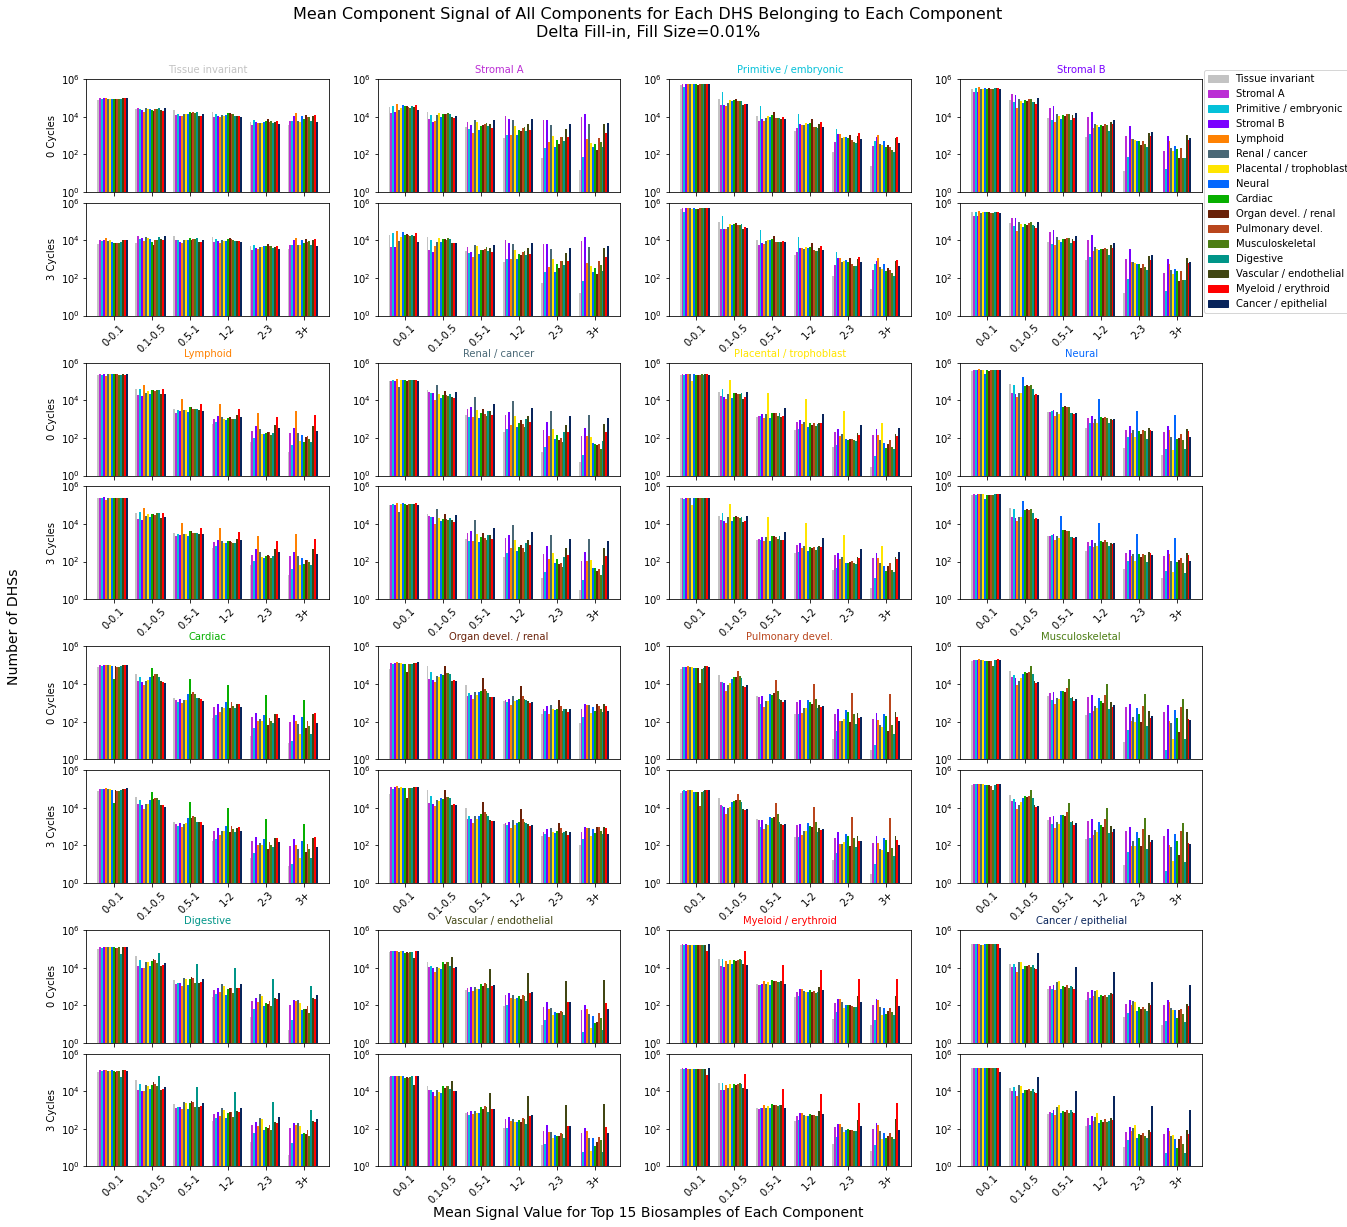

In [57]:
nrows = 4
ncols = 4
naxes = 2
bins = [0, 0.1, 0.5, 1, 2, 3, 1000.0]
fig = plt.figure(figsize=(20, 20))
fig.patch.set_facecolor('white')
for i in range(16):
    ax = axes_grid.Grid(fig, (nrows, ncols, i+1), (naxes, 1), axes_pad=0.15)
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_0_cycles[i][j], bins)

        ax[0].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[0].set_ylim([1, 1000000])
#     for j in range(16):
#         hist, b = np.histogram(all_reference_comps_mean_signal_1_cycle[i][j], bins)
#         ax[1].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
#     for j in range(16):
#         hist, b = np.histogram(all_reference_comps_mean_signal_2_cycles[i][j], bins)
#         ax[2].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_3_cycles[i][j], bins)

        ax[1].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[1].set_ylim([1, 1000000])
        
    if i%4==0:
        ax[0].set_ylabel('0 Cycles')
        ax[1].set_ylabel('3 Cycles')
    
#     if i//4==3:
#         ax[1].set_xlabel('3 Cycles')
    
    ax[1].set_xticks(list(np.arange(6)))
    ax[1].set_xticklabels(['0-0.1', '0.1-0.5', '0.5-1', '1-2', '2-3', '3+'], rotation=45)
    ax[0].set_title(nmf_comps[i], fontsize=10, color=color[i])

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, nmf_comps, loc = (0.893, 0.745))
fig.text(0.515, 0.09, 'Mean Signal Value for Top 15 Biosamples of Each Component', ha='center', fontsize=14)
fig.text(0.07, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Component Signal of All Components for Each DHS Belonging to Each Component\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.515, y=0.93)
plt.subplots_adjust(wspace=0.2, hspace=0.2)
plt.show()

In [13]:
#making ROIurls for the top dropped DHSs (best cases)
print('Dropped Cycle 1:')
for comp in range(16):
    top_100_identifiers = all_comps_average_signal.loc[DHS_metadata.loc[DHSs_dropped_cycle_1[comp]]['identifier']].sort_values(['comp'+str(comp)+' mean'], ascending=True).iloc[:100].index
    top_100_inds = DHS_metadata_identifier_based.loc[top_100_identifiers]['ind']
    top_100_new_comp_inds = new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered[top_100_inds]
    #finding the new comp for each dropped DHS
    change = []
    new_comps = []
    for new_comp_ind, identifier, dhs_ind in zip(top_100_new_comp_inds, top_100_identifiers, top_100_inds):
        #if the DHS is dropped
        if np.isnan(new_comp_ind):
            new_comps.append('Dropped')
            change.append('Dropped')
        else:
            #if the DHS is not dropped
            new_comp_ind = new_comp_ind.astype(int)
            top_dhs_comp_ind = int(all_comps_average_signal.loc[identifier]['max signal'].strip('comp').strip(' mean'))
            new_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(new_comp_ind)+' mean']
            old_comp_ind = original_decomp_Mixture_top_comps[dhs_ind]
            old_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(old_comp_ind)+' mean']
            #if the new component has the largest mean signal for that DHS
            if top_dhs_comp_ind == new_comp_ind:
                change.append('Optimal')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' #')
            elif new_comp_signal > old_comp_signal:
                change.append('Agreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' +')
            else:
                change.append('Disagreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15])
    original_chr = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['seqname'])
    original_start = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['start'])
    original_end = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['end'])
    drop_info = [new_comps, original_chr, original_start, original_end]
    print(nmf_comps[comp])
    print(make_roi_url_dropped_DHSs(1, nmf_comps[comp].replace(' ', '_').replace('_/', '')+'_best_cases', drop_info))
print()

print('Dropped Cycle 2:')
for comp in range(16):
    top_100_identifiers = all_comps_average_signal.loc[DHS_metadata.loc[DHSs_dropped_cycle_2[comp]]['identifier']].sort_values(['comp'+str(comp)+' mean'], ascending=True).iloc[:100].index
    top_100_inds = DHS_metadata_identifier_based.loc[top_100_identifiers]['ind']
    top_100_new_comp_inds = new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered[top_100_inds]
    #finding the new comp for each dropped DHS
    change = []
    new_comps = []
    for new_comp_ind, identifier, dhs_ind in zip(top_100_new_comp_inds, top_100_identifiers, top_100_inds):
        #if the DHS is dropped
        if np.isnan(new_comp_ind):
            new_comps.append('Dropped')
            change.append('Dropped')
        else:
            #if the DHS is not dropped
            new_comp_ind = new_comp_ind.astype(int)
            top_dhs_comp_ind = int(all_comps_average_signal.loc[identifier]['max signal'].strip('comp').strip(' mean'))
            new_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(new_comp_ind)+' mean']
            old_comp_ind = new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered[dhs_ind].astype(int)
            old_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(old_comp_ind)+' mean']
            #if the new component has the largest mean signal for that DHS
            if top_dhs_comp_ind == new_comp_ind:
                change.append('Optimal')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' #')
            elif new_comp_signal > old_comp_signal:
                change.append('Agreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' +')
            else:
                change.append('Disagreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15])
    original_chr = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['seqname'])
    original_start = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['start'])
    original_end = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['end'])
    drop_info = [new_comps, original_chr, original_start, original_end]
    print(nmf_comps[comp])
    print(make_roi_url_dropped_DHSs(2, nmf_comps[comp].replace(' ', '_').replace('_/', '')+'_best_cases', drop_info))
print()

print('Dropped Cycle 3:')
for comp in range(16):
    top_100_identifiers = all_comps_average_signal.loc[DHS_metadata.loc[DHSs_dropped_cycle_3[comp]]['identifier']].sort_values(['comp'+str(comp)+' mean'], ascending=True).iloc[:100].index
    top_100_inds = DHS_metadata_identifier_based.loc[top_100_identifiers]['ind']
    top_100_new_comp_inds = new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered[top_100_inds]
    #finding the new comp for each dropped DHS
    change = []
    new_comps = []
    for new_comp_ind, identifier, dhs_ind in zip(top_100_new_comp_inds, top_100_identifiers, top_100_inds):
        #if the DHS is dropped
        if np.isnan(new_comp_ind):
            new_comps.append('Dropped')
            change.append('Dropped')
        else:
            #if the DHS is not dropped
            new_comp_ind = new_comp_ind.astype(int)
            top_dhs_comp_ind = int(all_comps_average_signal.loc[identifier]['max signal'].strip('comp').strip(' mean'))
            new_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(new_comp_ind)+' mean']
            old_comp_ind = new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered[dhs_ind].astype(int)
            old_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(old_comp_ind)+' mean']
            #if the new component has the largest mean signal for that DHS
            if top_dhs_comp_ind == new_comp_ind:
                change.append('Optimal')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' #')
            elif new_comp_signal > old_comp_signal:
                change.append('Agreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' +')
            else:
                change.append('Disagreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15])
    original_chr = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['seqname'])
    original_start = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['start'])
    original_end = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['end'])
    drop_info = [new_comps, original_chr, original_start, original_end]
    print(nmf_comps[comp])
    print(make_roi_url_dropped_DHSs(3, nmf_comps[comp].replace(' ', '_').replace('_/', '')+'_best_cases', drop_info))

Dropped Cycle 1:
Tissue invariant
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Tissue_invariant_best_cases_CT20220113.bed
Stromal A
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Stromal_A_best_cases_CT20220113.bed
Primitive / embryonic
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Primitive_embryonic_best_cases_CT20220113.bed
Stromal B
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Stromal_B_best_cases_CT20220113.bed
Lymphoid
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_

Neural
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Neural_best_cases_CT20220113.bed
Cardiac
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Cardiac_best_cases_CT20220113.bed
Organ devel. / renal
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Organ_devel._renal_best_cases_CT20220113.bed
Pulmonary devel.
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Pulmonary_devel._best_cases_CT20220113.bed
Musculoskeletal
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_f

In [14]:
#making ROIurls for the top dropped DHSs (worst cases)
print('Dropped Cycle 1:')
for comp in range(16):
    top_100_identifiers = all_comps_average_signal.loc[DHS_metadata.loc[DHSs_dropped_cycle_1[comp]]['identifier']].sort_values(['comp'+str(comp)+' mean'], ascending=False).iloc[:100].index
    top_100_inds = DHS_metadata_identifier_based.loc[top_100_identifiers]['ind']
    top_100_new_comp_inds = new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered[top_100_inds]
    #finding the new comp for each dropped DHS
    change = []
    new_comps = []
    for new_comp_ind, identifier, dhs_ind in zip(top_100_new_comp_inds, top_100_identifiers, top_100_inds):
        #if the DHS is dropped
        if np.isnan(new_comp_ind):
            new_comps.append('Dropped')
            change.append('Dropped')
        else:
            #if the DHS is not dropped
            new_comp_ind = new_comp_ind.astype(int)
            top_dhs_comp_ind = int(all_comps_average_signal.loc[identifier]['max signal'].strip('comp').strip(' mean'))
            new_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(new_comp_ind)+' mean']
            old_comp_ind = original_decomp_Mixture_top_comps[dhs_ind]
            old_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(old_comp_ind)+' mean']
            #if the new component has the largest mean signal for that DHS
            if top_dhs_comp_ind == new_comp_ind:
                change.append('Optimal')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' #')
            elif new_comp_signal > old_comp_signal:
                change.append('Agreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' +')
            else:
                change.append('Disagreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15])
    original_chr = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['seqname'])
    original_start = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['start'])
    original_end = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['end'])
    drop_info = [new_comps, original_chr, original_start, original_end]
    print(nmf_comps[comp])
    print(make_roi_url_dropped_DHSs(1, nmf_comps[comp].replace(' ', '_').replace('_/', '')+'_worst_cases', drop_info))
print()

print('Dropped Cycle 2:')
for comp in range(16):
    top_100_identifiers = all_comps_average_signal.loc[DHS_metadata.loc[DHSs_dropped_cycle_2[comp]]['identifier']].sort_values(['comp'+str(comp)+' mean'], ascending=False).iloc[:100].index
    top_100_inds = DHS_metadata_identifier_based.loc[top_100_identifiers]['ind']
    top_100_new_comp_inds = new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered[top_100_inds]
    #finding the new comp for each dropped DHS
    change = []
    new_comps = []
    for new_comp_ind, identifier, dhs_ind in zip(top_100_new_comp_inds, top_100_identifiers, top_100_inds):
        #if the DHS is dropped
        if np.isnan(new_comp_ind):
            new_comps.append('Dropped')
            change.append('Dropped')
        else:
            #if the DHS is not dropped
            new_comp_ind = new_comp_ind.astype(int)
            top_dhs_comp_ind = int(all_comps_average_signal.loc[identifier]['max signal'].strip('comp').strip(' mean'))
            new_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(new_comp_ind)+' mean']
            old_comp_ind = new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered[dhs_ind].astype(int)
            old_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(old_comp_ind)+' mean']
            #if the new component has the largest mean signal for that DHS
            if top_dhs_comp_ind == new_comp_ind:
                change.append('Optimal')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' #')
            elif new_comp_signal > old_comp_signal:
                change.append('Agreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' +')
            else:
                change.append('Disagreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15])
    original_chr = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['seqname'])
    original_start = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['start'])
    original_end = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['end'])
    drop_info = [new_comps, original_chr, original_start, original_end]
    print(nmf_comps[comp])
    print(make_roi_url_dropped_DHSs(2, nmf_comps[comp].replace(' ', '_').replace('_/', '')+'_worst_cases', drop_info))
print()

print('Dropped Cycle 3:')
for comp in range(16):
    top_100_identifiers = all_comps_average_signal.loc[DHS_metadata.loc[DHSs_dropped_cycle_3[comp]]['identifier']].sort_values(['comp'+str(comp)+' mean'], ascending=False).iloc[:100].index
    top_100_inds = DHS_metadata_identifier_based.loc[top_100_identifiers]['ind']
    top_100_new_comp_inds = new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered[top_100_inds]
    #finding the new comp for each dropped DHS
    change = []
    new_comps = []
    for new_comp_ind, identifier, dhs_ind in zip(top_100_new_comp_inds, top_100_identifiers, top_100_inds):
        #if the DHS is dropped
        if np.isnan(new_comp_ind):
            new_comps.append('Dropped')
            change.append('Dropped')
        else:
            #if the DHS is not dropped
            new_comp_ind = new_comp_ind.astype(int)
            top_dhs_comp_ind = int(all_comps_average_signal.loc[identifier]['max signal'].strip('comp').strip(' mean'))
            new_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(new_comp_ind)+' mean']
            old_comp_ind = new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered[dhs_ind].astype(int)
            old_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(old_comp_ind)+' mean']
            #if the new component has the largest mean signal for that DHS
            if top_dhs_comp_ind == new_comp_ind:
                change.append('Optimal')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' #')
            elif new_comp_signal > old_comp_signal:
                change.append('Agreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' +')
            else:
                change.append('Disagreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15])
    original_chr = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['seqname'])
    original_start = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['start'])
    original_end = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['end'])
    drop_info = [new_comps, original_chr, original_start, original_end]
    print(nmf_comps[comp])
    print(make_roi_url_dropped_DHSs(3, nmf_comps[comp].replace(' ', '_').replace('_/', '')+'_worst_cases', drop_info))

Dropped Cycle 1:
Tissue invariant
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Tissue_invariant_worst_cases_CT20220113.bed
Stromal A
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Stromal_A_worst_cases_CT20220113.bed
Primitive / embryonic
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Primitive_embryonic_worst_cases_CT20220113.bed
Stromal B
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Stromal_B_worst_cases_CT20220113.bed
Lymphoid
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F

Neural
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Neural_worst_cases_CT20220113.bed
Cardiac
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Cardiac_worst_cases_CT20220113.bed
Organ devel. / renal
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Organ_devel._renal_worst_cases_CT20220113.bed
Pulmonary devel.
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Pulmonary_devel._worst_cases_CT20220113.bed
Musculoskeletal
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle

In [68]:
mask1 = DHS_metadata['start']==185149920
mask2 = DHS_metadata['end']==185150500
mask3 = DHS_metadata['seqname']=='chr3'

DHS_metadata[mask1 & mask2 & mask3]
#chr3:185149920-185150500

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component,ind
2300485,chr3,185149920,185150500,3.9403673,0.38103,4,185150180,185150000.0,185150286.0,Cardiac,2300485


In [69]:
print(nmf_comps[np.argmax(decomp_Mixture[:, 2300485])])
print(nmf_comps[np.argmax(new_decomp_Mixture_all_delta_0001_1_cycle[:, 2300485])])
print(nmf_comps[np.argmax(new_decomp_Mixture_all_delta_0001_2_cycles[:, 2300485])])
print(nmf_comps[np.argmax(new_decomp_Mixture_all_delta_0001_3_cycles[:, 2300485])])
# new_decomp_Mixture_all_delta_0001_3_cycles_sum[3185010]

Cardiac
Digestive
Cardiac
Cardiac


Text(0.5, 1.03, 'Number of Samples for DHSs of Each Component\nDelta Fill-in, Fill Size=0.01%')

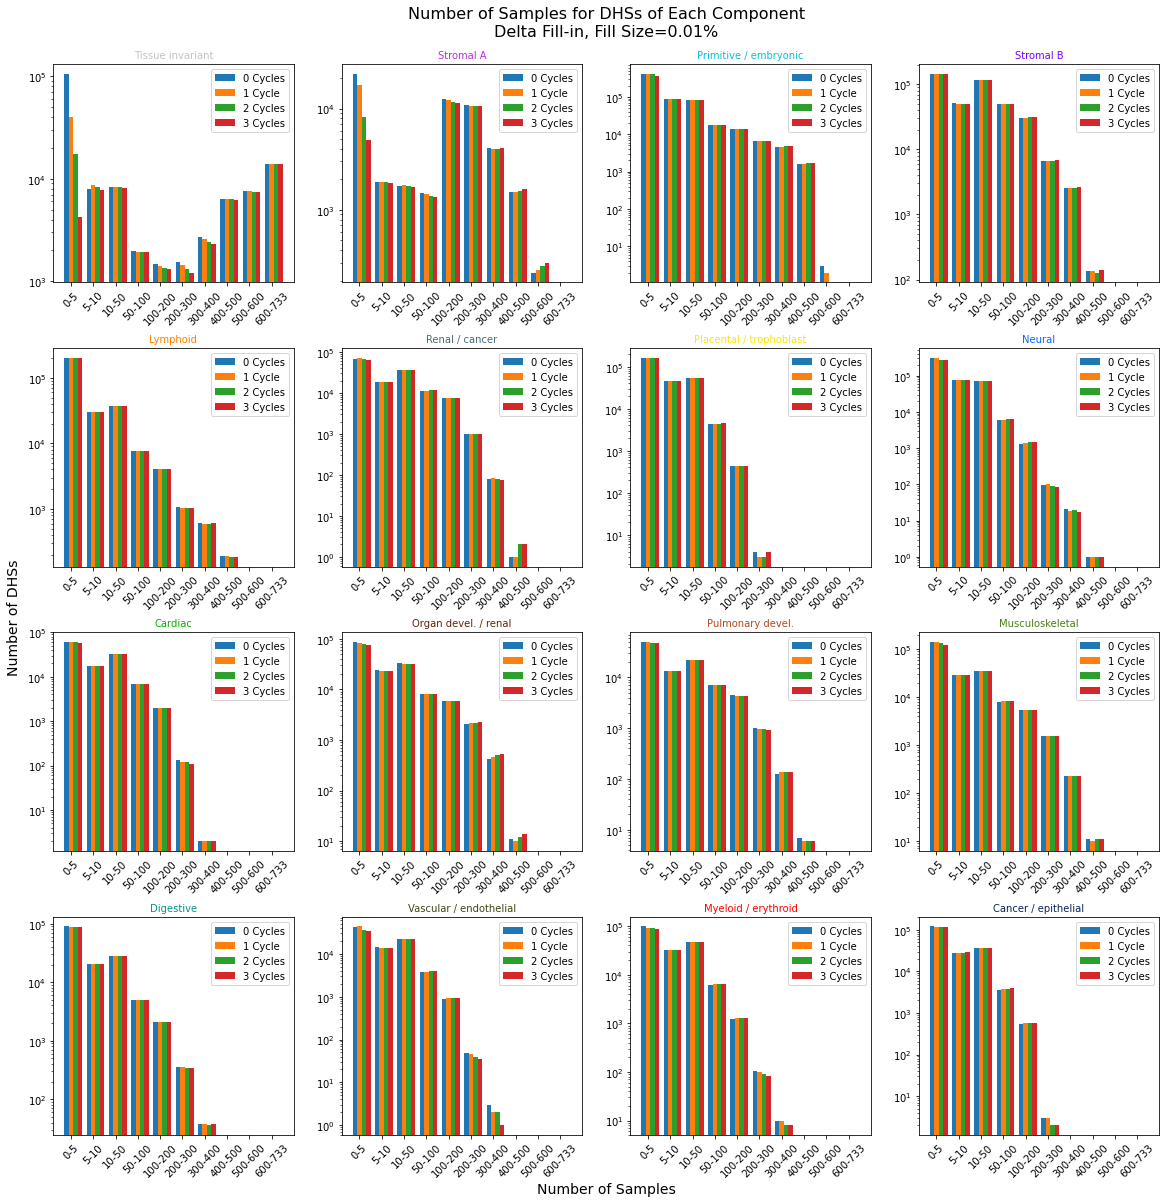

In [35]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.3)
fig.patch.set_facecolor('white')

bins = [0, 5, 10, 50, 100, 200, 300, 400, 500, 600, 733]
axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    data = [DHSs_for_each_comp_numsamples_0_cycles[ind], DHSs_for_each_comp_numsamples_1_cycle[ind], DHSs_for_each_comp_numsamples_2_cycles[ind], DHSs_for_each_comp_numsamples_3_cycles[ind]]
    hist, b = np.histogram(data[0], bins)
    ax.bar(np.arange(10)-0.2, hist, width=0.2, log=True) 
    hist, b = np.histogram(data[1], bins)
    ax.bar(np.arange(10)-0.0, hist, width=0.2, log=True)
    hist, b = np.histogram(data[2], bins)
    ax.bar(np.arange(10)+0.2, hist, width=0.2, log=True)
    hist, b = np.histogram(data[3], bins)
    ax.bar(np.arange(10)+0.4, hist, width=0.2, log=True)
    
    ax.set_xticks(list(np.arange(10)))
    ax.set_xticklabels(['0-5', '5-10', '10-50', '50-100', '100-200', '200-300', '300-400', '400-500', '500-600', '600-733'], rotation=45)
    
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])
    ax.legend(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'])
    
fig.text(0.5, 0.0, 'Number of Samples', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Number of Samples for DHSs of Each Component\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.03)

Text(0.5, 1.03, 'Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%')

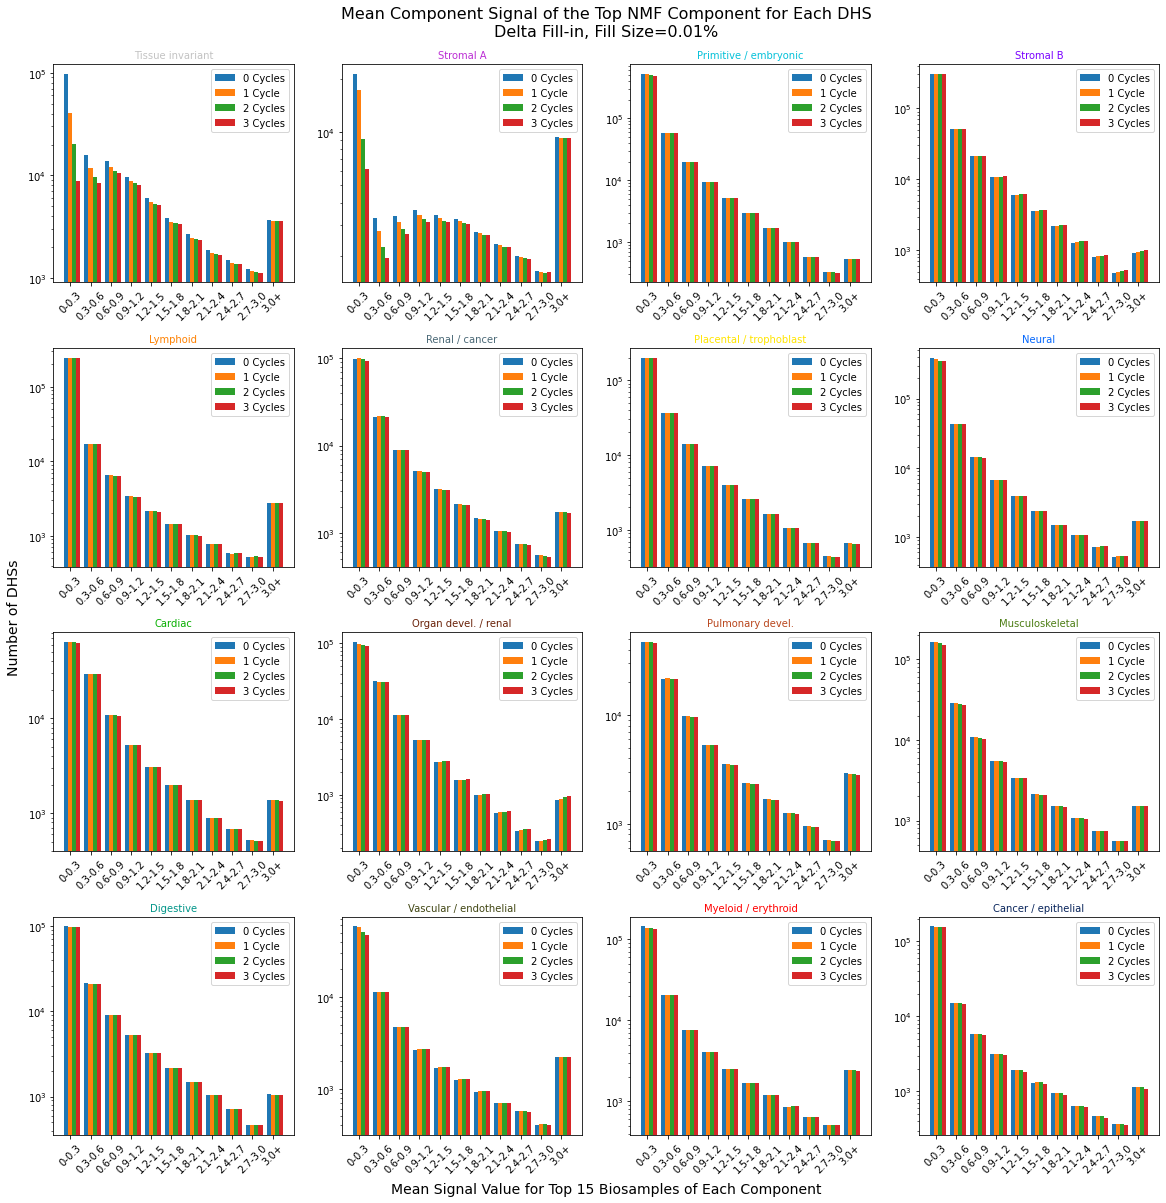

In [88]:
#with 3.0+ bin
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.3)
fig.patch.set_facecolor('white')

# bin_max = [3, 5, 2, 2.5, 1.5, 3, 2.5, 2, 3, 3, 4, 2, 3, 3, 3, 2]
bins = [0, 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3.0, 1000.0]
axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    data = [DHSs_for_each_comp_mean_comp_signal_0_cycles[ind], DHSs_for_each_comp_mean_comp_signal_1_cycle[ind], DHSs_for_each_comp_mean_comp_signal_2_cycles[ind], DHSs_for_each_comp_mean_comp_signal_3_cycles[ind]]
    hist, b = np.histogram(data[0], bins)
    ax.bar(np.arange(11)-0.2, hist, width=0.2, log=True) 
    hist, b = np.histogram(data[1], bins)
    ax.bar(np.arange(11)-0.0, hist, width=0.2, log=True)
    hist, b = np.histogram(data[2], bins)
    ax.bar(np.arange(11)+0.2, hist, width=0.2, log=True)
    hist, b = np.histogram(data[3], bins)
    ax.bar(np.arange(11)+0.4, hist, width=0.2, log=True)
    
    ax.set_xticks(list(np.arange(11)))
    ax.set_xticklabels(['0-0.3', '0.3-0.6', '0.6-0.9', '0.9-1.2', '1.2-1.5', '1.5-1.8', '1.8-2.1', '2.1-2.4', '2.4-2.7', '2.7-3.0', '3.0+'], rotation=45)
    
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])
    ax.legend(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'])
    
fig.text(0.5, 0.0, 'Mean Signal Value for Top 15 Biosamples of Each Component', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.03)

In [84]:
#Without 3.0+ bin
# fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
# fig.patch.set_facecolor('white')

# # bin_max = [3, 5, 2, 2.5, 1.5, 3, 2.5, 2, 3, 3, 4, 2, 3, 3, 3, 2]
# bins_manual = [0, 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3.0]
# axes = axes.ravel()

# for ax, ind in zip(axes, range(16)):
# #     bins = range(0, int(np.ceil(max(all_comps_average_signal['comp' + str(ind) + ' mean']))), 10)
# #     bins = np.arange(0, 3, 0.3)
#     bins = bins_manual
#     data = [DHSs_for_each_comp_mean_comp_signal_0_cycles[ind], DHSs_for_each_comp_mean_comp_signal_1_cycle[ind], DHSs_for_each_comp_mean_comp_signal_2_cycles[ind], DHSs_for_each_comp_mean_comp_signal_3_cycles[ind]]
#     ax.hist(data, bins=bins, log=True)
    
#     ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])
#     ax.legend(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'])
# #     print('%s 0 cycle mean signal average: %s' %(nmf_comps[ind], np.mean(DHSs_for_each_comp_mean_comp_signal_0_cycles[ind])))
# #     print('%s 1 cycle mean signal average: %s' %(nmf_comps[ind], np.mean(DHSs_for_each_comp_mean_comp_signal_1_cycle[ind])))
# #     print('%s 2 cycle mean signal average: %s' %(nmf_comps[ind], np.mean(DHSs_for_each_comp_mean_comp_signal_2_cycles[ind])))
# #     print('%s 3 cycle mean signal average: %s' %(nmf_comps[ind], np.mean(DHSs_for_each_comp_mean_comp_signal_3_cycles[ind])))
# #     print()
    
# fig.text(0.465, 0, 'Mean Signal Value for Top 15 Biosamples of Each Component', ha='center', fontsize=14)
# fig.text(-0.02, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
# plt.suptitle('Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.465, y=1.03)

Text(0.465, 1.03, 'Average Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%')

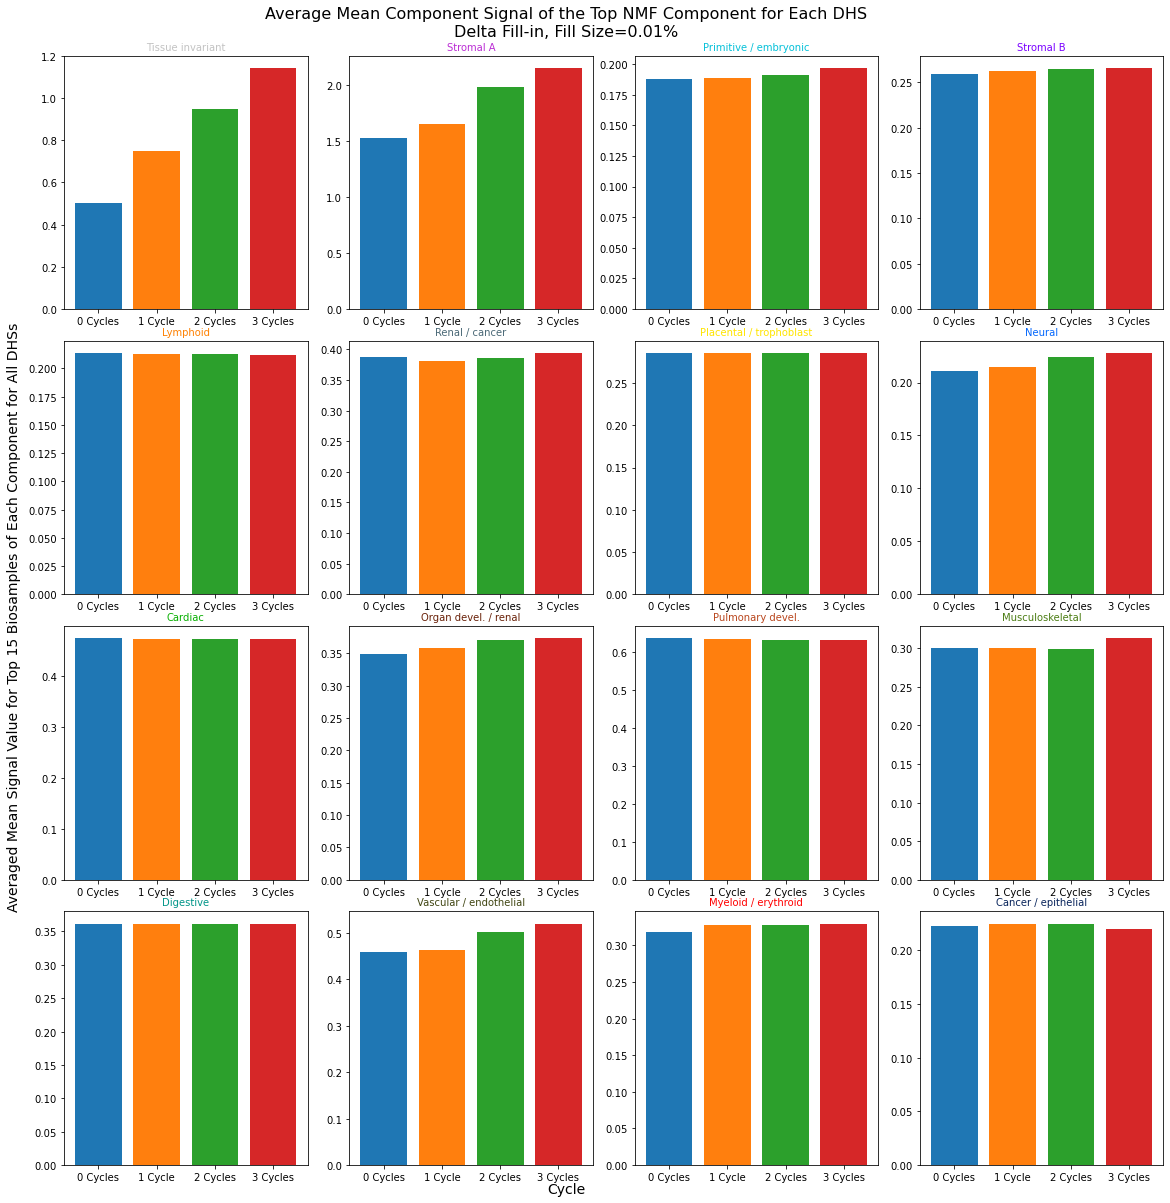

In [75]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
fig.tight_layout()
fig.patch.set_facecolor('white')

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
#     bins = range(0, int(np.ceil(max(all_comps_average_signal['comp' + str(ind) + ' mean']))), 10)
    bins = np.arange(0, 3, 0.3)
    data = [np.mean(DHSs_for_each_comp_mean_comp_signal_0_cycles[ind]), np.mean(DHSs_for_each_comp_mean_comp_signal_1_cycle[ind]), np.mean(DHSs_for_each_comp_mean_comp_signal_2_cycles[ind]), np.mean(DHSs_for_each_comp_mean_comp_signal_3_cycles[ind])]
    ax.bar(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'], data, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])

fig.text(0.465, 0, 'Cycle', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Averaged Mean Signal Value for Top 15 Biosamples of Each Component for All DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Average Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.465, y=1.03)

In [10]:
#creates ROIurl links for recommended DHSs
def make_roi_url_dropped_DHSs(cycle_num, comp, drop_info):
    today = date.today()
    bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_dropped_DHSs_cycle_' + str(cycle_num) + '_from_' + str(comp) + '_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(100):
        f.write(drop_info[1][i] + '\t' + str(drop_info[2][i]) + '\t' + str(drop_info[3][i]) + '\t' + drop_info[0][i] + '\n')
    f.close()
    link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_dropped_DHSs_cycle_' + str(cycle_num) + '_from_' + str(comp) + '_CT' + today.strftime("%Y%m%d") + '.bed'
    return link_path